# D50 · 프로젝트 ⑥ 제약 챌린지: 인터넷 없는 현장용 오프라인 비서

**음성 AI 전문가 과정 · Day 50 / 51 · 4시간 (50분 × 4교시)**

> 🎬 **애니메이션(과제 브리핑):** [animation.html](https://imguru-mooc.github.io/AI_Voice/day50/animation.html) · 📝 **워크시트:** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day50/worksheet.html) · 런타임: **CPU** (GPU 없이 진행)

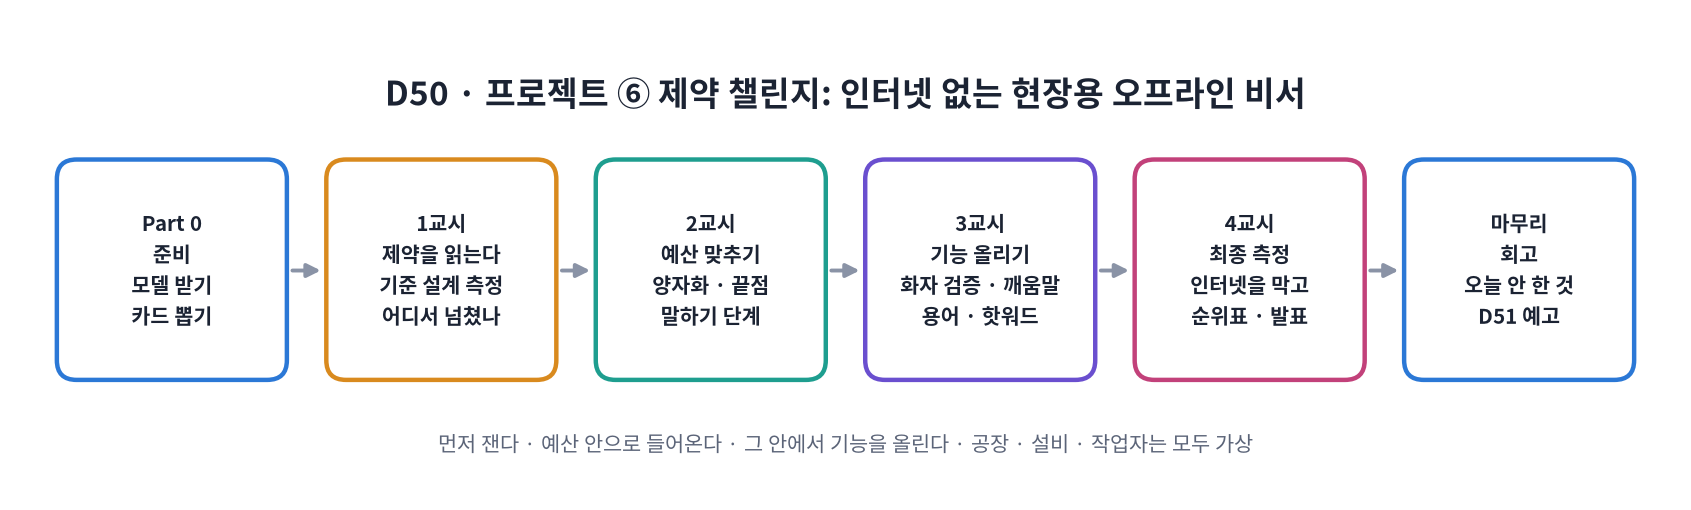

## 오늘의 과제

인터넷이 닿지 않는 공장 안에서 쓰는 음성 비서 **'하나'** 를 만듭니다. 작업자가 "하나야, 3번 펌프 상태 알려 줘"라고 말하면 소리로 답하고, "하나야, 5번 압축기 정지 기록해 줘"라고 말하면 작업 기록에 남깁니다. **등록된 작업자의 목소리에만** 답합니다.

기능만 만들면 끝이 아닙니다. 팀마다 **제약 카드**를 한 장 뽑습니다. 카드에는 예산 네 가지가 적혀 있습니다.

| 예산 | 뜻 | 어떻게 재나 |
|---|---|---|
| **모델(MB)** | 기기에 넣는 모델 파일의 합 | 파일 크기를 더함 |
| **RAM(MB)** | 돌아가는 동안 가장 많이 쓴 메모리 | 새 프로세스에서 부품을 모두 올리고 한 번 돌린 뒤 잼 |
| **지연(초)** | 말이 끝난 뒤 첫 소리가 나올 때까지 (중앙값) | 끝점을 기다린 시간 + 받아쓰기 마무리 + 화자 검증 + 첫 소리 만들기 |
| **명료도(CER%)** | 비서의 답이 알아들을 만한가 | 답을 소리로 만들고 다시 받아써서 틀린 글자의 비율 (20% 이하) |

| | 어제 (D49 레드팀) | 오늘 (D50 제약 챌린지) |
|---|---|---|
| 지킬 선 | 사람이 정한 선(안전 루브릭) | **기계가 정한 선(예산)** |
| 확인 | 다른 팀이 공격 | **자동 측정 셀** |
| 점수 | 통과율 · 발견 보고서 | **기능 시나리오 15개 × 예산 준수** |

## 하루의 흐름

| 교시 | 하는 일 | 내가 쓰는 것 |
|---|---|---|
| 1 | 카드 뽑기 · 시나리오 듣기 · 기준 설계 재기 · 어디서 넘쳤나 | ✍️ `violations` · `percentile` |
| 2 | 예산 맞추기 실험: 양자화 · 끝점 · 말하기 단계 → 설계 v1 | ✍️ `first_chunk` · 🏁 설계 v1 |
| 3 | 기능 올리기 실험: 화자 검증 · 깨움말 · 용어 맞추기 · 핫워드 → 설계 v2 | ✍️ `cosine` · `who` · `heard_wake` · 🏁 설계 v2 |
| 4 | 최종 측정(인터넷을 막고) → 제출 코드 → 반 순위표 · 3분 발표 · 회고 | ✍️ `final_score` · 발표 카드 |

**규칙**
- **최종 점수** = 기능 점수(시나리오 15개 가운데 통과한 비율 × 100). 예산을 **하나라도** 넘으면 절반으로 깎습니다. 예산을 넘는 제품은 현장에 넣을 수 없기 때문입니다.
- **바꿀 수 있는 것**: 설계(`dict`)의 값 열 가지와, 내가 쓰는 함수 네 개(`who` · `heard_wake` · `first_chunk` · `cosine`).
- **바꿀 수 없는 것**: 시나리오 음성, 설비 목록, 채점 기준, 카드의 숫자.
- 측정은 몇 번이든 해도 됩니다. 제출 코드는 마지막에 한 번 만듭니다.
- 공장 · 설비 · 작업자는 모두 **가상**이고, 목소리와 소음은 **합성한 것**입니다.

---
## Part 0. 준비

모델을 받는 지금만 인터넷을 씁니다. 받은 뒤에는 인터넷 없이 돌아가야 합니다. 4교시에 인터넷을 막고 확인합니다.

> 🎬 **애니메이션 D50-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#flow)

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1분 안팎)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile sherpa-onnx==1.13.8
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, math, time, zlib, base64, tarfile, warnings, importlib, urllib.request
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display, Markdown, HTML
import sherpa_onnx
import importlib.metadata as md
warnings.filterwarnings("ignore")
SR = 16000
print("sherpa-onnx", md.version("sherpa-onnx"), "· CPU", os.cpu_count(), "개")

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if all(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    def same(a, b):
        if isinstance(a, float) or isinstance(b, float):
            try: return abs(float(a) - float(b)) <= tol
            except (TypeError, ValueError): return False
        return a == b
    w = list(want if isinstance(want, (list, tuple)) else [want])
    ok = len(items) == len(w) and all(same(a, b) for a, b in zip(items, w))
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {str(got)[:110]} · 기대 {str(want)[:110]} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def tool(ok, mine, ref, name):                           # 내 함수가 통과하면 내 것을, 아니면 주최 측 도구를 쓴다 (아래 셀이 멈추지 않게)
    print(f"🔧 이후 셀은 {'내가 쓴' if ok else '주최 측의'} {name}을(를) 씁니다."); return mine if ok else ref

def play(y, sr=SR, label=""):
    y = np.asarray(y, np.float32).reshape(-1); print(f"🎧 {label}  ({len(y) / sr:.1f}초)"); display(Audio(y, rate=sr))

In [ ]:
# 📼 음성 풀기: 등록 음성 4개 · 연습 음성 8개 · 시나리오 음성 15개 (가상 · 합성한 목소리. 글자가 긴 셀입니다. 실행만 하세요)
_META = json.loads(zlib.decompress(base64.b64decode(
    "eNq1l91OE0EUx19lsteE7He33nijT+Cl8aKRVRtIi92CJoakSMECG8XIQoldrLGh1UBSoJI21hfaOfsOzrS6H6V1d7bL3XS3mfM7/3Pmf2Yfv+"
    "HyS9w9xD0UuAXEFchSEjKyTNZGoUR+iTxZlvXXZfonOP0Ix9tweoDwp0v81Qa7iqBRda0Gwj++w46Jz87hdBvv1/B+a5FuaKzquWWdbsQ5g4pr"
    "1fFefRSoWNbpQ7pezhdGCHqhVFxZ4TYWkAcl/oMSM4KkzoCqt8im+ANBsWrQJDR158pEY9bRjybs/UyPSfKEkkSNvwOhcNci2UCjxQAlx6neHE"
    "IlYHrAB1pKlEQPStACUFT+t3WwhgtIwVc1gmbBjeX0uwi2Nt2tBnlg4mYLQavOXLwlfT0M5LWTpGWFaCCJArnvTfeQSNa0oF1BBIyU07V66QBJ"
    "bAqJI4V+dTCplN2Do54n0lEPW+Z91qLd4vHaSJaVQBvN4hEoD77ugT3EX86JRgfOVQXBSRV/M/8vFTua4kmlaqo8h1Qz+wlO+vimAnY/NpPqMY"
    "miojLLlT5QZroNpNXg7EAa24mbsADnegjHvXSZHvm2JGpqhtEF5vYko5wrrxn0if5yLb9KHwUChEED00+VtaTtlcwapnCG9w+j+kamkKl4F6cz"
    "ibK3woShfbdTJUlNfT5N1Rh3+vjinXPZxWfDCPpwvDC64qPzgUsIg97xvTpS+ZL+tFhailCevl3XC+ObSDA4ffPqRTEcKZSsZ7OyIrGbSBxjYy"
    "rVlHQnShXOlYYPJOnHCiXpW7eiyTzrYY/jlJFnfkpiE2c+mNg4ZHRi3ggQBYWfMZPm91hn0IHPFdw+QHC8A7YZzCv/vFAs6WGqrEfFy7MO0PjC"
    "TI8K7J+DXUH4glzoOwNSz1h+ysgk8B5TVs2q6Q6myDFZ0p+tGRNAAtv9JsHBS4Tlz8WsoMmpzsVEPP7wUyUl2p/kEc/WrtPdTP6dQzoK7x0iqL"
    "bwoBoGzBnLYb4ZH4eCsKik0FlTW9/dJIntmBNNz3D5EbwJJ0pKDFFxu0aaDbd3//YbAvv3aM4lmGcrOaPMbTz5A3QI1Ww="
)).decode("utf-8"))
_OGG = base64.b64decode(
    "..."
)
print(f"음성 {len(_META)}개 · 깨끗한 목소리 {sum(m['n'] for m in _META) / SR:.0f}초 (소음은 다음 셀에서 섞습니다)")

In [ ]:
# 📥 챌린지 도구 · 모델 받기 (한 번만 · 1 ~ 2분). 인터넷은 여기서만 씁니다.
_LIB = (
    "eNq1fet3XMW153f9FeeeLK7PMa12t/zAtGnuNUbcsHhlbEIm02h6tbqPpLb6lT6tF47ukkFwHTDBBgkLIjkiGGwS34lsDIiJmQ8z/wkf1a018y"
    "fM77er6pw6rZYfxGEldp967tq1a9d+1bbrus2JiVq1ERSnSo1SurXg/O/vnGePZpze5npv9Qend+ti98ut3vUlp/vB8s43N3NOb2N7d3mru/yd"
    "07vyTvfdFWd3bbl39Yvep185vbVruyvL3Y27aON0v1/uLa87B3ZX17pvrh0YUs04fG/5Girl15s3u1cv9jYw+p9vdC9fcna2lnpvne9t3Nn5ej"
    "OFwq9672D+m71Plhz86m1I293Vr3rLt3ZX152d22/1rr7dfe9C971radd1h6r1VrPdcZphymkHKafaTDnhAj7Ohs1GyulU6yh8o1YdTznjpTA4"
    "diTlTJXCKSkIO+2Zcgd/z4y32s1yEIZmtMZMHXgphU6jNTR05rSTd7LHMpnM0Mkzp4vPPs9vt96sBLXwUDgVtFul4WajMT+M8YJSvdqYHH6j2p"
    "potutBe3i6ibLG8Ehm5Mhw5thw9pg79OqrZ+41yEwraHeajWp5+PBwpxMOVxud4+x/bDhzdDibdYfOvFZ87vkXR9H/nFsu1VstNxeNdLgStoLS"
    "dNAu4u+gPFWUBrWZsBjOFt+YGi43itlj08PlZr3ebKQ5oZty3E61U2oEHWucRlBvFoNGUdcUw3qpVlPtF2UBhOAMQCi4lZl2qVNtNoqtdlCplj"
    "vNdpogx4MH8x0MVcbAfTWzAVsXgxC7VNrTb7a5p8uQY//nAjtpbjNbzwBhaF6sNirBPHqNVxtqkGo5kI+xoV+dfIFIcxV59lbvukOj/+WXz/9C"
    "EHm4e/uCs/v7i6BmoqG3uQqq5AgjrOj97Ub39iaItPfxHVV9aec2CPTaZTbJskn36zu9jbvdP95k/c7Xd3tX7oBYfwBVs8lRGWV1tfft6s72lp"
    "nh+pK7KEv5mT4G+qAMvfzKL18mWNPpsFWrdjy/kB3LOdMOiAp/VhuOAL7o/N3//Uyv2fnxnQ8dCwdDo6+Nvvyq2mCz2E+Wu59f5GI06CmzTuD2"
    "5LOvPX9KkWRy7UTG1tLO9zjGd2SR5CvXL/SWt3ufrqSt0dAQR7r33rrTu7sOHIEdLfeuXHLU7NizRJcI/ehmBsF+8Wtx6FevnH5h9PQZBc337N"
    "t9dw11BXc0y8ajI+4Y/upurYLD9davqarDUnXEHVt8eCSa3bt6uXfl7d7VS+Re3Y9udT/bcMjBlm8NnTn5a4GnHUzMhIGsVuq7l9bjbt3rF53e"
    "R9tO78IaCi/03v3GMDqABj4STgs+v9vWdEJeDI6JYQRTV96Jezgamd3rl3orQMEdp/f53QiF5iC5c1MlOfa9q2sY6W8A+lrvyoUHHcZxG81ac1"
    "IGWF3uXT/vYOMIDfY6AQ025bVXFIE88fDY7btXehtr8T3hgGZ317aHTr148vTzr/66+Orof9Vk+7D4jQ4wsZogYgd7u/vWunXvkOIsluAkjkj3"
    "i7saD7sf983xQFvXz+dkoyLewY7qyAwE64HPkDrnZjTcwMnV/RR6GBs6Pfpc8ZnRl0/9HDuQSR85+jBHaHurd22Jf+18TaC5472rW9jfa73vsV"
    "3vre9sLXu9Oxf8tCO8RDUELfTeeR/n2OEX9jWf7OEcUq23PhwaeubkmdEXn39ZsalS2CbdTrQOj8gtNYXzVQlRNIKvetCZalZYP9kOgspCMQxK"
    "7fIUG041O3PNtrQskIsEjUqriTsK39k0+07MvPHGAr4yyW10w1mOpy7sFD+LnSk2Sx9NyVVWDDtBi8Me5yDVdohbN2h0cHOSXTxXqoXB4tDQqZ"
    "OnnxXOJoO7J1F1zm2U6sJSen86T2mpt7lE8ewdYda4Fhus+39//OOXQiAQu97f9l56xkfp4WwGRadPvqS/jx3lN2ird2VLcE18pDPS7W2S9gfL"
    "3qnR049JeWZRrdB9JgkEThvFu69WONWXN/uA+GoPEEczfUCM/BQgTiWA6H6/2f0CZ23jcve9b/oguHFfCI5n9kKQTT9xHwieTaJhc7n7LdAAQD"
    "76ax8EX+zdiJH74yCbPr4/BItDz/zy2X8bfbX4wuivNf+Lx7eG7ht1wIBjQ0NDlWDCqbRLcxAf2xWvA6nWz6lFuu7uxSUeqe6XuDrvdj/DKf3+"
    "TvejdYfSOcluY9np/nAZjAWswtvZ+kQoUrXHn1/dcXAZO6ZcuvoiyHP4acpnJ5859axbwJHytKSeDqdKWYEiDRG72vL8tJInPXemMzF83PX99F"
    "QwX6lOQpT0/BSEdd95zDkyJmO2g85Mu+FMpxxKp54coML0mK+XWZ4KytPFShBWJxue+iteK3g12Aq5hzCRrzfJ2/XtIRz89kpvfRmC3QXoPyLa"
    "fL0tbBLXITkmV3vzTu/Kf7D77ntL3c1tdBPevXqxu3kNIsySUWQ4ZYUn++BBw6hSzsGDCqTFE1BfWFuwhEBV5VQn8Nlodlhkeqqlowa9ck67VA"
    "0D57VSbSYYbbebbW9CqOOLO8L+l6/hBtBbBApGj0XR1OKLUpqZ+loVSDbz+Iuur7A8UwtCwudVCsJbxwiOF/FXSvEutoZ1HO4AKw443bVL8sXq"
    "A6xnd8OL1RDZFFny4ZRzxI/5NDtlnX93jqBP8rbkAJp9axD2sHDoONWJalApjoOkTLkfsX0BKNEphnNQ1wN7YaiG1UYIzakcEJzoysB94RF90E"
    "tnWrXA951So+JAs7I7TIliqqqmDMHLpk/JptvjqVa1oOH1FT+Vdw5nrNtKZJptXAuXHCrX717bfXfbO5zZ2VqnaH59yb/fGqJrjmvA3ylnotYs"
    "dfQSMukRTploxwLFtk0ZgWDLf2c52M/95lQ36eAJ9XS6iazX3L0yDSY5bOgJN6+Qglac5fKV3ZTLON5crezedz/V1X1PuHQTfmXNZW/gyt5v/F"
    "gYwByYQg2d1UNbtTL8iC0+mHORHRHJCJLdhTWDhj6ZQp2OV9szMJCIdOHvkTs4GhsYDEkz11fMZa7dbEzyxNfDSSHPJlgsf2NYxQ3AfsiWmtMR"
    "N5I+A/hRgtEuO7ufrNLmZORVXJrO4/g/mJKbPgtK8mQc37f5ewX8vFwrhaGjzVsRE/9x/cL/3f5AxEAyahEtFUeLzVpbO7e35Oa6/jt1c6WFcX"
    "+8Dc0ubsgWvY+2yLipi4C7w/7V/WKNjbpvrhtOrlg57pZikYhsF4teGNQm9LUiqFBmprBZng46USkbpYuwXakfZSBXtUjrvyBBNAKxWOlv8MJO"
    "UNTFsMEMRWNx+vEamnkHS7xGpn2D9lfOaJxHeIlWd4fr311bSihHmsELgIOgAZQy0Yl9oTItonH0lnGZCWTNVzsaVwC5dH98PRxyiM4+DGsZgB"
    "YugTCoeNblPxgx5gKHIrS5LvJPRD1QOSBHUSvScoC51/fC32kv5PoXsgdiz3ODefCoWoDV1XF1Hc/4yqbZnOnkR/x0udYMA88/YTAqB1SGDebL"
    "QatjNpumzCDXj39XLcrlicU94wWUiX7m/Liy9Kj+F905Ykl+lCMr2a0G26oX6i3Tq2oHaRh0vbZb+O+Z4SdPDv+30vAbOKDDu1c/H+Ptj/+Hkf"
    "AXtD1YZGATXmiZUfABSlFDow4IV7/Z5IRIaCIBtUuNycDj1TvlgztlNTciI6ymnBJxGsCMHMA4GngYNGuRMyylsxBHC5kxJy9/gc1HlRzhLKzV"
    "yRGmZISo51nV8yx6wuDsScHjvGrwyxl2svqLzfHLKzn/hDPYxzALw2h2yKmX5iljcSVt3yDmbKnejBBLoX8V9oQlMWZtXhBSvwMb3i2RE69dNr"
    "/+9DZ+aa1g9/JdYaM0eXS3PuZ1pIhBRJHvtrsXl9AsOiEgaN4lYxESyyLthDHSmqiHKOOVge9hJzN/8hQM8hGDmFBXb9N5yslms0+M5GTExymQ"
    "uhQ1Uqg6dMg5evw4b0NXWW69JtQEFrFqRNf86W1p/BgLxqIJYBQPZMx0qdWCQEMwbGyixkJdsUISAeMdj1Eozg5ggMgDFiB/E0sfLon9CIaO3d"
    "9Dg7js7NzagoSWdg4oI88BmhLV7/MHqDJlI5RxeOBEtqoE2OXH+GAaHR9Ao/NJCis9PI0uJEcY/7todJ40ujCARjVeISY35zxKsxC5KOdZqH3z"
    "FgxSjjbsw+C1C5vVp1+J4XdFY1sjNqdpWFSb/3NFjeR43Teh3dyNFVE9P5VQok9xAM4NOe+g7gTog+En/egOKbU1dPR4aBjzmRhKFmsJxGFDcX"
    "HZsFGMUJAnFUun99nWztb5WJk2C/BFpsFdjSMHYYRHTY2UEouiKn252Qiidc0Buoi7yXoMeyN0oB3eklzxHH6PQ53GJweI6UbEO6EriPYW7+jw"
    "VDYUlcVUVNEEqg4EZy9Uc1W0aoz59uGVqaqhzIVTjn5PSVnOAFGxt0W1jntRypSelJOlEKxA04shFjnBai1qw1pVCEdl9AgTO2bxvD8swybsaO"
    "Kiif/TO933t6Qx95AlcG+Ke2Nj5/ZFMZbKYRaFGZ5Kb89u0ng5eGcGIbtMZAuISYwKrZWTYNvYrOxBircfgnGw/QjJHoi37PdjGr6nCNn9SDzb"
    "DEua6vu43dYfet/fSNJnySbLcZpSut+CoikpeSDsQ8AaWmwsH0JVfBQN3+csZAd93F8Dylp10+25CgQBiqEr+McfvZxDK/g3EAW3P3N6W9v0Ge"
    "yu3sAJ9XZXP+m9taG/5IC/8w2cC9RtaC7689+MIgEHOFzbvBxWlvxHLilBkIFcCS0zsG8lfYM0WulSWGq3SwusVOpsyi4dN6U2xqUE+P5XjHHI"
    "8dAcWlepNpluwPONCwl8sq8MAojhloRnbqrpBXWMHTTazVotIOec0pBpgiR/iWung4V8rVQfr5ScRs5eUmKUAliLP4hb7NuBDUBWT+cx/x4KZ6"
    "8pnLdKcQ5+dU8dOeEtQSUpeMZ8jp7mBF8t5MgiWewr44wewJpDad7lqZnGNMTOVm1hr1QrruC26/3LU/lC+l/+acx/PXzcZdgDWhtDkY8DjVHp"
    "iHnuZeUCBZ7dnME4bULRanRxXBBZAAQOXW2VLD7ygwOGCtKHnvXISb5enS82mtB4vQVI/I02lb5oy8jeVXSKCjKBAPA/5G798w/Cs5Zh5r36GS"
    "p8HskzL58mw+9ev9r7Fk615avGRtBbvdr98BoFuUz6MEViGl2u3Oyti6G4e3nFVgLb6qjh8qw062mAWJqpdYrtxqQngKm7t52mHajCDeGZKdVE"
    "/lig+PYkQlB8nMnOQivgcZMDeHhE0XpDDQ7dcbZZm0W9HGCQcehRvKVTiaEdeTekf0L1WViIOpUhvzUowxXw/UbQbobeEfGCWPNA3pPvfarHDC"
    "AHZdDwN+0OoazzECzAAuGMEI5shj897Id8sMg0aqhGibPrLVDOagxctjo7+KrAYNXxmpOTxfGFToDrHHZcYz2INO+ZRmWiWguoCYcTavmgCO5J"
    "OJGmTdmrNtPPsP/zr8RjYdEVTpx39bQu9glGpoBjonPeOXPa6C8QZUWFSTmZ6Aav8wYnOPEFTrPOQqGVa2Fh9YKLyJSxE+gJVUV92Rd5PT2Jlb"
    "mTpZaLW/oBPOU3trv/+R8iA97NOTu4gP+wROEFRCp+4N/dFSPX8ueKgBNWyPIAYigXcgCqPANz7pi19xSLUU6wxsDmz5z2+wilXDDdcmO2oCeS"
    "HL0wdaCx2im4tN3mraMKoQY9QR3a9OlF2vzrz2rlHfVV2PZ9HgnKBfqbggwGtTS0ameAhvaIude3S7sfXsg5lHYQAPHRFp3uj5qRBfMk4SLioU"
    "rjnsRnpbiYmJONt4K0lHvGcNuqBuXA11703Xc2d8/DWX6XcQCQQiQ+4X/ehcrjsKeMa1x5m+e142539S+9P1yEc07UKazt05VYJKPQ0ASODTRu"
    "e9z11SHivtL5D5NUcy5UKn1k4psttbmn4zOwuFQtLWGWp5C9opK5KZ5V2p5ze4gU3QvVMc6DM5M9gd6/hehadv4ZYuETz+F6fcoJYYxk7ROJzj"
    "hQZQiFmfnjmZyhilmqtUPxlFU0UApzPDHkjpSsysBP6E84WMQcClHrPP003Q/89c/WnDR4k0WMJNfQGDSYXK9cXKQf6QU2+pcwQT05m3NwUDvV"
    "xkyQqD+rcC/7D/ZWRvShVirAldKZRFu14LN6wQKAn9sTegKj/tkYWmmFEi6f6xcEmOUnFm8jYRAWzH+1xuAJBjbm8ic4GNYva6Quyx6Fs7mzwF"
    "qtMYaLNeEaHjjOWWK21thTF9QicI/m7g0BLEwGvSqOND3TaJWgUrpPTYBL2VAdGROpbF9AjtwLDpBq8QExpGxUMuTxRCWPouGKnk0bvj+UnDKe"
    "sZ9EBzQ8mlMkeqTPSlaNIRAuIXejO+dS5MbeIEA2b3YnPdeu4qJxtV9nwj3XWny9cy5cfL3hygXaAqRicsASkqKBGCxZauxDYbvIGz70YFEqa0"
    "oOJ+YZUmAFkXIH2YALUF5pJfK7qtqeoQBwdMTv4qFzjcXhoNUsTw0/+eRwaXZyOHsOgy8qKBvK06yjXHlRKSqUn1wZfvm0dyWG7DSng0aY7sx3"
    "JOiiiIqUUzzzGv54VYLYzi2m9P/1GiENFLFOWWFeQU+lSVzi+awIPnBg5/e4vI0bOO/5fXKRRB4XuXTjozNtRW1WA5LjDPaa2/ZCkor746ebdC"
    "pF1wctIWoQKr+D/ecIu3O6iIe4ThPK51awGWMObtNeJkHnZkgxItAloy7dlfMmbg1MKQIeN4KiFjJlfBBjSqLQ6PINtrQz3jNdNZUxqgJddVwF"
    "9yZeK/YZciEHxN6if5Ocu4/+TjjTc7KF9nVg5sj1M3Xxk4bpVqkzlYYbLOyEnhtdzpT9EkKATUTR5U9Ss7okrxwI/TwHZv4iHaqJ6Br3t/oIRm"
    "gwMTbJ4JpC7jjp2BWqTcwhR50T3e+s42j3TcUBUZqEWdAnwmIENdGbV1NEZcLH8hJoIGjAjEUEg3fyRAbAwJ8Ka/mB2OHGFrDRFEOtw5B+pUEf"
    "8mmc4slGFVJveqLdrBc7UN7CygzdRurw5jv0eutznzd0IR+GPnD280ImsJMXzVlNEOLQ3x3GHYqTsEgrfJ5MZAKOxJl2AGtEPX88o2EiZjSDMJ"
    "QPv/BcgqlG6DDaFUiRfJZrsUyjKvaWgmQmnaXeu/KVs7uxRsc4lAux8G1FQvEd5U7/gAFPsJNp22jO8eANSUkkKQ/z+Q140KmoMDwcvneGqVDn"
    "/mhTR3LG4idPNyAy/lL17MLz97FRK/05JS84LPkGF2KZLlLYPWYDPtbwiLgFLX6xsaW4KFGJc1bDIndtgc4xKVDbbYAIVR/qOXTTpvGWg0anGY"
    "YBUDYePGukWGVH+rVq6VNttGY6oP5GFSRa0St9WJgiQ1KZSiV6hDA/oNJYjlKDIIat1fi1Jto4eMXKuGfowLgKFsR9BoydcAJngO5fyEGzZ/0Y"
    "VAQwm5ZYJ/Dti8IPaxoYXj7rK4dKdiQB7khG2xGbk9mM8lCLTqRDiopQMmnfMd+WAfr8BtQdUNpS79v1nCEzkBLiUxkUTkqDX0XcRHhW9A28Lw"
    "xQjEYCVTsquhuGWvGu3KJ2J4HoNs3eBHUfoMFXu/xl/gHEruBR0VYqavmiOGq6N7fFDHXtMgEwcc9rKlIQd2ZM9hWqXdYunKAJtqmtSti2MpQ/"
    "kIRXoR8ug+pOszWw8smjrKSXWw3wOK1XR4Fnjz2GVanaBXk/Q5cDJn8afaCUVObVoHPgloGnGkTyLa4ykgQa+VqU1Pu4kLKCExqBjCn6PQ0znk"
    "E66QSnlAENM41IIew70xhcuSPx97DyIlrnWnckJAo26IpKwmMN2tr3MYuezgs8MaSFnCcswNdUmxI91CbKaDHGBNXg5VhslWZobbRoEKaXKOQo"
    "8hdt36EhRoWy/2P2Nrlr993kfbc0cgH+43bjhG3q588Ua/ba72kszPzD7De7n6wwTIXM4ssNhjJg5+CY+UdYc8h7w1kRlO4riovYZiTQM6/FaM"
    "VHgZX9UssZ9fhvtD4eVHjfj85DYuEjO++BWp1qNiaqk8qqk9fRkmqepPSSTWpiETSGOXNgLQrap8G82RHb+O3PYPT3eleX8Yqmu/KVr733tEJ1"
    "t1Z2/tfd/aQG1TM1UDIISMg2hk/c4ypGRTDfL0Tsd0Uv7H8R60tPuco4YrOOVoEXJq2iNsaC+122XAOCOr37kojbcSMKgdIYk0i9X6BVUZGvds"
    "Iz0QvTl7jRetMPHjw3nXOgWejnqdB4Z7V2Cwl3VkKPKYwnhNW9bz/z93sPaj8Hze//OLT/bWj+nq9FE0Dph6P5QS9IHUbK8s1o3n492vd4NL/P"
    "a1LhYKCUBWgh1stSPw21po69WrTUCmARobru2L674A0uThzBwU3sXYtfC+fryTM64vcdUgMRLQ1nfvHKC6MvK/VUEZw8G9beTYkkzuOl9ATltb"
    "wKDo6OsYlhUkeZx/U6tPLN/Y5r9pgz/fM3YnHnurEKMJTCPsPmTQjjzMCB9Vf3vRsIDJYwnttr8MdJqJQOEzZv3ZSG0R9r2XdWtB1ArZCSh6wy"
    "VvZlrYyMsLV+haf4UE32bee/BY1AUbveD3CJyXRY5d0rDx7ls6XEnWw6w09uksytJSAFB2sC8mFx2dZwtfKt0HTTje0HIFjN3YQz3IO1cRCS96"
    "QCz3itJxkbtk8n4T1mpoW+oIC00i/DvfxMI8+0EA2U1iLbWiJCA7RnmByreFVv9gdPV0q1RCNOq4qpKKgBW83aAgV88uDELPt6QtX9KBtnFHsO"
    "UOn03VlxC3UiRkeftQ/EOLjSlFeaLFUb/SfgHs8Pc4y5lwDgyytatCelHtFkzNMCol3+qyNPxnkWJGQIuoM+BzIiIipXPwGRQ+pJPotkEOXWhz"
    "GpA/MEkGTrTrgW2WIxlqorZ9tV7yIlHkkBZr/4jE47Zd0YkUJyBT1A7827TvxEfJ+no8mBGDvEK6QYC4xHrahKBalhlCqiRPTGSpWhEyE1AdNm"
    "ItmmXIPSavc/5ESvT1PqVeWRdKZfUImGevSipHqk/KjFRWhHQVtCAryBQWqRkUViS5Wi0V3/G4lOfHzb+/FlxLni5UJKP0dOMTHHzq07sSgVhw"
    "lKBIvS25oizkvknASYMk8BDQcGLFgAfjNTpWbCGnFes0/EZCVwzVWPo12rnx2vlrMZi+rAhAFQwq//bt8+UUg7XoB00Ep5vKJgOhHTZg3oKreB"
    "NZQ9o1oAbd/BbDwsrCawNtKqyWr8NdsfTO/pB/rGmqvGUa4FeWXv93eOlqfecd8fH9FMoIfOTBhDw2Z+DLxMauCxcZE4DAqqxBjRE5qfIzNMzO"
    "725nhJ67eHckOLDiXuZXlJiDU0QmWwZ+ibWF1AnjoeLg4AtELmQJF+/8sZyNjxYxA1mwnZKoq8JfPkZVm55BOaingF9z7rPKGq0U09s9RBUjSD"
    "eiwEnzq36C8mBxNXUeR4UePrF476GYn9YjEuMm8QjXvBlFuv9GK6G+fVd44BEQxlyDFQQtTsjgqwjhe9qNdgYteSHgZxRYnaVa2I10xnwjACam"
    "5AxIhkScjZORLIyZPZKxyVqGed98/uB7/b+W5T629JuVtJDWL0K6gHNjTEe0odNOvnYzxY5WFoHZPwD9oZ/NioAMDHtEUw4/ctNlJ5Z5NbBNug"
    "FWjwrzwd1bLCf0xQChR/z2kKBgQvBpYtMhoB2ZIqeh9jtdZE5KrVndDPGM6509AcKMCB7OCeUOk7EKVn0pWokDx1MF2JTdKf8V5KUB78yDJgv7"
    "kz8dDSf7AECz9e3nQSRtH4kpeLRQhcvxyACc8Qf0pB4jsPkcvhx8ufJUJi4jcciM6ZaVWMSJpXM2NR+fKMASEvf/IjnM1n6NcRgVf9VN6emJdZ"
    "7jNztgt2gOOYHbCp4zLjZ6O+n7Oigyzw/xTHTplcJpppKYvx1Qs6ytsOopKgUkLNDROaj8j9YVFo4Pg8aZmKyZ5oEC42IBB2Vh2nhtbaE0coUl"
    "Ut10bT0K8gj6Q5pgZK9ExZz1r9gRvK/eIfKY6Zl1hTtV3KxksDn4I7PcuXn4ACV+JhP7GRhEZHqSPfEQ6RDm+l81KnzoEucPLXBfPV90In6UGU"
    "/tGlizH2SFMWLTzQhlyjcKWjp2zCNh5jzCiBBfqG3htDIrZOyd5UEMDGTkQLhO1Fwuk1wHztcwB/gcoO+IvOubCzuDfjCyfFkPTP6xRI6va/91"
    "h7xPZBUTsqpVMBodE5DSKiOlx5ihtXDe2JWolQoEWmASjQPNtEpJxzlQwKFqjBdZUwyoJZZs1RSYWuXkIBCGTRT+BM+gA/ar2zsthlWewXd7nY"
    "Aal4nGhEyinnOCb0srX9EJJcl0iYe1cVQxRJq1E2pCXsnl40beSFA2rBB8YW91TIwlERw9IHbLJ9VMexkksQ0jDXoxCFnBuVsal/48IgF62Azb"
    "jaZBvrpAvG89G5gvchH8zGx1jixRM8xY4pH9PR7fJOZcCjdOUcEFDiYwf/2O2/aBtSTn4rFVZCRm7cRcIbrUxLfsANvtruvx6sJ/Yyp86yQEaJ"
    "WimKki2gMFmgFWsBKxctUD6tR7wzZDdyWXH1ojMnhkn1Pd8fyEaJ+bzF+fLyZ0pNmu8bT92M8mdKAZCXP/1+KSd+nohAEhhSGRybeF8QiSwUQu"
    "WnJDfiHkuhCkRW30wUINtu18i3H8k2ppxfvrGpwLODeA3EFrercHYPFupZH1jCfcoR+5kt6FMnwUtrOAsQI8AH+FA9tvCccknsKx+oxCq3liHp"
    "wLW7j/57jqFj+oJC4DZDuiuMFShNo7QGE8PuJ2u9NxHsL8lydKouZDvR2jGdp1SSvH01E7rwGM8pZiShdmUHNG+whM6lyAqVPcGpk+9glQ6gsJ"
    "J8DDuV1iKpDqT2lf893mC8KCgq2VieKZMRWCTHmKWm2WtytsB82EcHzUQXjhpWEwqo4fIQpNSACTrRo6qvew9r3xjJoRRhmaHka0w96dLCiq6S"
    "3/edQ3FvNUOMFXhJ49hYEgFts8CqTqap+/Y+2YayC/bimvn1wJo9eLGIYgT/GN8v2o/7DITRCLzAdZfk1fKibHQysQqeuaGniMnyJR+S5ET/Bj"
    "ugQHPImRCCMhftixZbsCJCz1HpVAe/qo69eD/Xda5WXRWhgrnjViUDnK6hJKUTKlq2KCLZquNFdZGFgcVekDYBdgPVUhcOjoWKfYc6hl31kdOr"
    "IJJXdVSvflx/29W7r4wvP25cdPfk0pIjiFYvJs+jklRfRMYhcrLmtFAKfpEk8Jt/7Qeh0e+aBf2TYPEJhBTJWwgel9IcCqztS8W7l7I3T/uSFG"
    "PidTJT99oFgqQMqu0oKDbJxVnEd1vC3VzVHd+GwWmU5fRK4VNHRICe5FAcUsuH3HrZHE1PLljon57NJIck/uRvSQcpp4qzkb/he+LRPxzrrV0Q"
    "/rz9GbNXPfLHY/Sx6XDORFKw/TN0JffBVn+BgDg41BiPiLiEcseEgsbnrhXHsegwrqlhCgn/7IT2z05wM6KkvGPmtlVrqI/vyWqmLHZd5NtROe"
    "Kc3YsXGYO7e/4mpkGaODqrMhkRrrZW+Dzv3e09T+PpLVZEROowsatg2SHCJb0JP4ZsVt59BcdIVAl/8gAkx/opfDLIWWd7ZMiA4Pqp783S9hZ8"
    "Eiv0rjBf0LvXjBlclimOQpVqurd2k6/s5XHuuvLAfMBc1/I8in6Xb9bBo+LMhUyYF7kl1Wg0ADAZteSkljEkp+jVrQfN4qbdkLEJMWk9HGA4TN"
    "oMtRpuhMe+KGVgLL4+Sm1e/XRxpyvIZx163LIKUt/FGeQ8gcJKfxnnvrRTXUoGKzeRptJfpMwTMsi0BL9eVfvI4gtGeJbJq52G5Aeb4EIIH2cA"
    "Xlgar0HqMkRTGg/5t1cUWigWeTSGh7HTmBKLACbKpZbEs0KMRWhFXiWtEgtS0l1VF6k8reLK8WjsF6MnXyi+9EzeK7xeSY89znyHfGBZ4fOpfg"
    "WhbhIknYZLFA5SnSUpogbDapD4Z/fiDZWTypPRgnabKkM0cmH4cCaTs8R77ovxRSoHFh724fC0vP5IGtOQ5M+Utjb9wzSPAOoF7TCOT/N732gz"
    "rUqMq7M5DvBEOsdhwxVpOem7vybhizqxq+Jb798w+VeRFNJ7zI8tv2kxFW/Q2UkDMTODbX7H2B3bBT9hebYj4uR6bPOrbVc3bxmYLC35eIFvo8"
    "JYJDZisQyZSPqblJugMRUjLczENMhYRuxhTpIsbYoSzZ1KhDo/1KPYMXl07VuGLFlqIUYB992+cC1HJ2zl5dCXCzdBCP0jRDzQRPshgHfCm8cl"
    "/xvz1EXShbU7sDvOc6XTOqguq8IduKSgWvN+o0LpAAVve0ydpMAQCSaZm8XcIfAh4eBFao6KGrZYr7qFu8vXdHJvIS/FDnVjqlwJxU+82CL5eU"
    "ooE2dlFF3LcTa3e2s3MIb/QDy1zuDJ+Lbrk4gSeVbjG6s+bpshRdyJ06+qZvGFwyZ9EqRpktgPteKCSERgW0eZrmvEV8kHrBolbNKgPdQn5fbn"
    "djVnvs9wQLFA7iM0oaVWw+a0njz6MPAhWPTe8C1aCQpmq82ahLqEnqYKuido104YEuwEpXZK2mpETHIFPS1d8WsskQMBPhhvYobPKBoyYV8SBF"
    "kT64VpSwsJM9ZGT1YcVL7/rIkUlzd5zB2rgI19iXWhZouU8c9ffAue98MKApQQEnpRwpB0clv1b1gwRSF/yUXA+Ax+RG9qRWW6tmxntRpvVsSz"
    "51JAVkC4ZW6rQOJSNDbguHWmD8YNXU/c0BYKF3kNS06G0FZ9WqZIC/ssq5kyJcGPJYRTF//Yx295e6l/ECM9fuyIfurDfydDwhfRN/QsyYHrGH"
    "jf9yfiBU3hvZB+gmm2oMJ/TIIloZ1d78I6cuLsXpYLqfvXbcnl/vUdmGnkNsIrko/V3aVz63M/upfXVFpLa6e83oW/aNsoD8HHdxDzEDuURQ6K"
    "dsC1xmKQ77uX8E4ek7p6W5DJWu8KX92pHelPmH08nU2wiqPHjg7IVn04OzBV8xM4UnoXjx+ThNLcvexhvWWZxeh59WCAbzLJsCR25xO4ixHcp+"
    "4Ld+ZYP9xHjg7IMH1kcIrp7IgFuDjiFOAjGvCRBIEVfgKFzf8E8pJTIlnMVFIbw0r0Q1w2MoluVMYGljC/RrsTzlUhcCo4yU3Nv38TkZXk/WQS"
    "5090FsxEphfCzcQToVoQAdJLilesoeQfhSOQBv3+l8k8HlWGOtCtXSyKialYrCOeq1h0o8S+FJohBM+KBeywFJsiBlexk5KVY/3UAi9qOkLzoK"
    "ge2L6j6k3NgEwkGX9P/hH88zcH6abbL94uKcj9ZMUG4CUfmw1pn6rtR5Uo7AcNRnPu/Q+PDLLFT83VzbsUS4t4rf7zX72UQ7Id7/WK6BDy1NE9"
    "ROXmEL0ch7Q91ORA8GPp3vgwJAG4paOSvvSDkO7134uT+X2VnGP1osjxkRI6/Yw2BakHtkaleSydRcTfY45HmCnSjRzx/aH/D5l/Ue0="
)
open("offline_hana.py", "w", encoding="utf-8").write(zlib.decompress(base64.b64decode(_LIB)).decode("utf-8"))
import offline_hana as oh; importlib.reload(oh)
from offline_hana import jamo_dist, BUDGET_KEYS
print(f"챌린지 도구: offline_hana.py ({len(open('offline_hana.py', encoding='utf-8').read().splitlines())}줄)")

REL = "https://github.com/k2-fsa/sherpa-onnx/releases/download"
os.makedirs("models", exist_ok=True)
def fetch_tar(url, folder, label):
    if os.path.exists(folder): return
    t0 = time.time(); tmp = "models/_tmp.tar.bz2"; urllib.request.urlretrieve(url, tmp)
    with tarfile.open(tmp) as tf: tf.extractall("models")
    os.remove(tmp); print(f"받음: {label} ({time.time() - t0:.0f}초)")
fetch_tar(f"{REL}/asr-models/sherpa-onnx-streaming-zipformer-korean-2024-06-16.tar.bz2", oh.ASR_DIR, "받아쓰기 모델(fp32 · int8 두 가지가 함께 들어 있음)")
fetch_tar(f"{REL}/tts-models/sherpa-onnx-supertonic-3-tts-int8-2026-05-11.tar.bz2", oh.TTS_DIR, "말하기 모델")
for name, path in oh.SV_FILE.items():                    # 화자 검증 모델 두 가지
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"{REL}/speaker-recongition-models/{os.path.basename(path)}", path); print("받음: 화자 검증 모델", name)
oh.export_vocab(f"{oh.ASR_DIR}/bpe.model", "bpe.vocab")   # 핫워드에 필요한 토큰 목록

ALL = oh.load_set(_OGG, _META)                            # 소음을 섞은 소리 y · 한 말 text · 말한 사람 speaker
ENROLL = [x for x in ALL if x["kind"] == "enroll"]        # 등록 음성: 작업자 두 명 × 2개
DEV = [x for x in ALL if x["kind"] == "dev"]              # 연습 음성: 작업자 4개 + 외부인 4개 (문턱값을 고를 때 씀)
SCENES = [x for x in ALL if x["id"].startswith("S")]      # 시나리오 15개 (채점에 씀)
SPEED = oh.bench()                                        # 이 기계의 속도 계수(기준 기계 = 1.0)
print(f"등록 {len(ENROLL)}개 · 연습 {len(DEV)}개 · 시나리오 {len(SCENES)}개 · 작업자: {' · '.join(oh.WORKERS)}")
print(f"이 기계의 속도 계수 {SPEED:.2f} (1보다 크면 기준 기계보다 느린 것. 계산에 든 시간을 이 값으로 나눠 기준 기계의 시간으로 바꿉니다)")
verify(len(ENROLL) == 4 and len(DEV) == 8 and len(SCENES) == 15 and all(os.path.exists(p) for p in oh.SV_FILE.values()) and 0.5 <= SPEED <= 4.0,
       "챌린지 도구 · 음성 27개 · 받아쓰기 · 말하기 · 화자 검증 모델이 준비됨")

In [ ]:
# 🃏 제약 카드 뽑기: 팀 이름으로 카드 한 장이 정해집니다(같은 이름이면 늘 같은 카드)
TEAM = "우리 팀"                                          # ← 팀 이름을 적으세요
CARD_ID, CARD = oh.draw_card(TEAM)
# CARD_ID = "C"; CARD = dict(oh.CARDS[CARD_ID])           # 강사가 카드를 정해 주면 이 줄의 주석을 풀고 글자를 바꿉니다

print(f"{CARD['icon']} {TEAM}의 카드: {CARD_ID} · {CARD['name']}")
display(pd.DataFrame([{"카드": f"{c['icon']} {k} · {c['name']}", **{b: f"≤ {c[b]}" for b in BUDGET_KEYS}, "우리 팀": "◀" if k == CARD_ID else ""} for k, c in oh.CARDS.items()]))
verify(CARD_ID in oh.CARDS and all(b in CARD for b in BUDGET_KEYS), "카드 한 장을 뽑음 · 예산 네 가지가 적혀 있음")

**카드 읽기**

- 네 장 모두 **CPU만** 씁니다. 숫자는 이 수업의 기준 기계에서 잰 값을 바탕으로 정했습니다.
- 카드마다 가장 빠듯한 칸이 다릅니다. 🟦 A는 저장 공간, 🟩 B는 메모리, 🟨 C는 응답 속도, 🟥 D는 세 가지가 모두 빠듯합니다.
- **명료도**는 네 장 모두 같습니다(CER 20% 이하). 빠르게 만들려고 알아들을 수 없는 소리를 내면 안 된다는 뜻입니다.

---
## Part 1. (1교시) 제약을 읽는다: 시나리오 · 기준 설계 · 측정

> 💬 **쉽게 말하면**: 예산을 받으면 가장 먼저 할 일은 **지금 얼마나 쓰고 있는지 재는 것**입니다. 가계부를 쓰지 않고는 어디서 줄일지 알 수 없습니다. 1교시에는 아무것도 고치지 않습니다. 듣고, 돌려 보고, 잽니다.

### 비서 '하나'가 하는 일

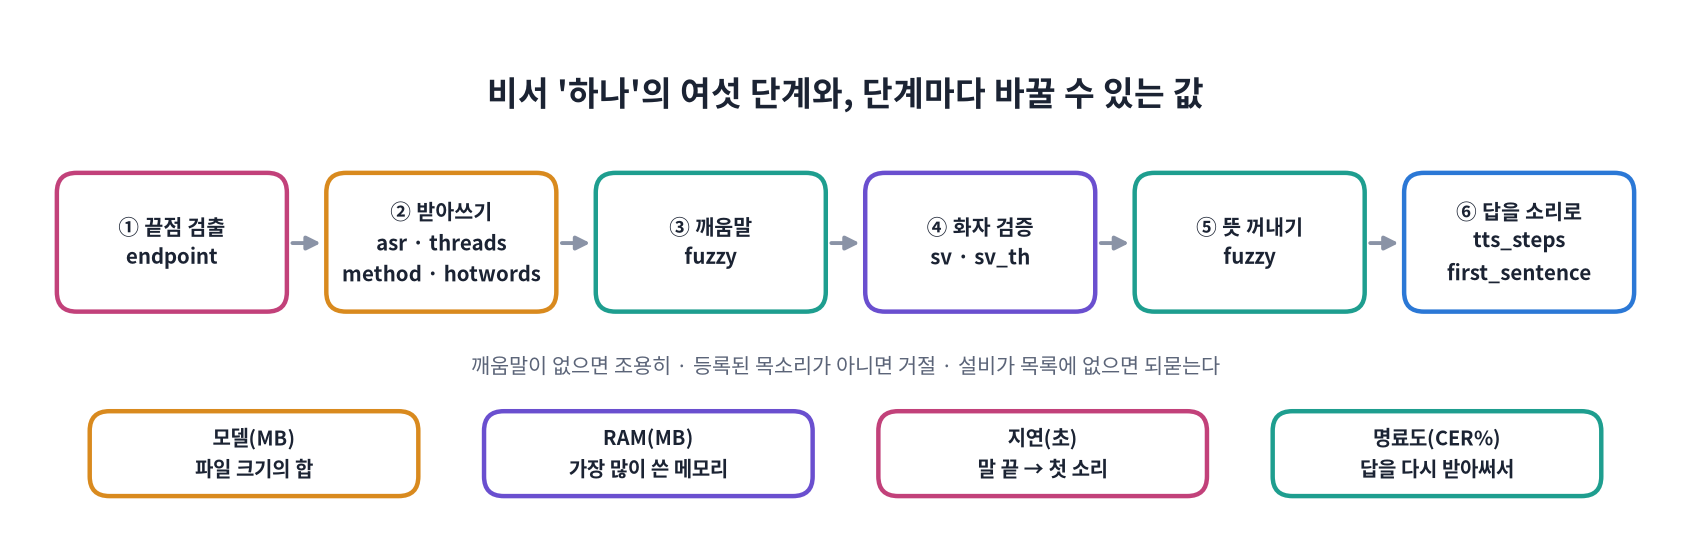

```
소리 → ① 끝점 검출 → ② 받아쓰기 → ③ 깨움말 확인 → ④ 화자 검증 → ⑤ 뜻 꺼내기 → ⑥ 답을 소리로
        (말이 끝났나)   (글로)      ("하나야"?)     (등록된 사람?)   (조회 · 기록)    (첫 소리)
```

- ③에서 깨움말이 없으면 **아무 소리도 내지 않습니다.**
- ④에서 등록된 목소리가 아니면 "등록된 작업자만 쓸 수 있습니다"라고만 답합니다. 설비 상태를 알려 주지 않고, 기록도 남기지 않습니다.
- ⑤의 명령은 세 가지입니다: **상태 조회**("… 상태 알려 줘") · **작업 기록**("… 정지 기록해 줘") · **마지막 기록 읽기**.

### 설계: 바꿀 수 있는 값 열 가지

| 이름 | 뜻 | 고를 수 있는 값 | 기준 설계 |
|---|---|---|---|
| `asr` | 받아쓰기 모델의 정밀도 | `"fp32"` · `"int8"` | `"fp32"` |
| `threads` | 받아쓰기에 쓰는 CPU 스레드 | 1 ~ 4 | 2 |
| `method` | 디코딩 방법 | `"greedy_search"` · `"modified_beam_search"` | 탐욕 |
| `hotwords` | 핫워드(빔 탐색일 때만) | 낱말 리스트 | `[]` |
| `endpoint` | 조용한 구간이 몇 초 이어지면 말이 끝났다고 볼까 | 0.2 ~ 2.0 | 1.2 |
| `fuzzy` | 용어를 얼마나 너그럽게 맞출까(음절당 허용하는 자모 수) | 0 ~ 3 | 0 |
| `sv` | 화자 검증 모델 | `"campp"`(28 MB) · `"titanet"`(40 MB) | `"campp"` |
| `sv_th` | 화자 검증 문턱값 | 0 ~ 1 | 0.5 |
| `tts_steps` | 말하기 모델의 생성 단계 수 | 1 ~ 12 | 8 |
| `first_sentence` | 답의 첫 문장만 먼저 소리로 만들까 | `True` · `False` | `False` |

> 🎬 **애니메이션 D50-2:** [제약 카드와 예산 네 가지](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#card)

In [ ]:
# ⭐ 먼저 듣는다: 등록 음성과 시나리오 네 가지
by = {x["id"]: x for x in ALL}
play(by["E1"]["y"], SR, f"E1 · 등록 음성 · {by['E1']['speaker']} · \"{by['E1']['text']}\"")
for i in ["S01", "S04", "S14", "S12"]:                    # ⭐ 평범한 조회 · 머뭇거림 · 큰 소음 · 외부인
    x = by[i]; play(x["y"], SR, f"{i} · {x['speaker']} · {x['note'] or '평범한 명령'} · SNR {x['snr']} dB · \"{x['text']}\"")
table = pd.DataFrame([{"id": x["id"], "말한 사람": x["speaker"], "한 말": x["text"], "특징": x["note"], "기대하는 일": {"status": "상태를 알려 줌", "record": "기록을 남김", "ignore": "조용히 있음",
          "refuse": "거절함", "reask": "없는 설비라고 되물음", "last": "마지막 기록을 읽어 줌"}[x["kind"]], "말 안의 가장 긴 쉼(초)": oh.longest_pause(x["y"])} for x in SCENES])
display(table)
verify(len(table) == 15 and sum(table["말한 사람"] == "외부인") == 3 and table["말 안의 가장 긴 쉼(초)"].max() >= 0.45, "시나리오 15개를 봄 · 외부인 3개 · 머뭇거리는 말이 있음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
for i in ["S01", "S04", "S14", "S12"]:
"말 안의 가장 긴 쉼(초)": oh.longest_pause(x["y"])
```

**해설**: 시나리오 15개가 오늘의 **기능 시험**입니다. 고르게 섞여 있습니다.

- **S01 ~ S04, S14**: 상태 조회. S04는 "하나야" 뒤에 잠깐 머뭇거리고, S14는 소음이 큽니다.
- **S05 ~ S07**: 작업 기록. 누가 기록했는지도 맞아야 합니다. S06도 머뭇거립니다.
- **S08 · S09**: 깨움말이 없는 말. 비서는 **조용히 있어야** 합니다.
- **S10 ~ S12**: 등록되지 않은 사람. **거절해야** 합니다. 설비 상태를 알려 주면 정보가 샌 것입니다.
- **S13**: 목록에 없는 설비(4번 냉각기). 비슷한 다른 설비로 알아들으면 안 됩니다.
- **S15**: 마지막 기록 읽기. 앞에서 기록이 하나라도 남아 있어야 통과합니다.

표의 마지막 열 **말 안의 가장 긴 쉼**을 눈여겨보세요. 대부분 0.1 ~ 0.3초인데 S04와 S06은 0.5초가 넘습니다. 2교시의 끝점 실험에서 이 숫자가 중요해집니다.

</details>

In [ ]:
# ⭐ 기준 설계를 돌리고 잰다: 기능 점수와 예산 네 가지 (처음에는 30초 ~ 1분)
LOG = []                                                  # 실험 기록
FNS = {}                                                  # 내가 쓴 함수가 통과하면 여기에 넣습니다. 비서가 그것을 씁니다
check = oh.ref_violations                                 # 예산 검사 함수(✍️ 1을 통과하면 내 것으로 바뀝니다)

def run(design, label, show=False):                       # ⭐ 설계 하나를 시나리오 15개에 돌리고, 예산을 재고, 기록한다
    try:
        d = oh.check_design(design); res = oh.run_scenarios(d, ENROLL, SCENES, FNS); m = oh.measure(d, res)
    except Exception as e:
        print(f"⛔ [{label}] 실행하지 못했습니다 ({type(e).__name__}: {str(e)[:160]})"); return None, None
    over = check(m, CARD)
    LOG.append({"실험": label, "통과": res["passed"], "기능 점수": res["score"], "외부인 통과": res["leaks"], **{k: m[k] for k in BUDGET_KEYS}, "예산": "✅" if not over else "⛔ " + " · ".join(over)})
    print(f"📊 [{label}] 기능 {res['passed']}/15 ({res['score']}점) · 외부인 통과 {res['leaks']}건 · 모델 {m['모델(MB)']} MB · RAM {m['RAM(MB)']} MB · 지연 {m['지연(초)']}초 · 명료도 CER {m['명료도(CER%)']}%"
          f" → {'✅ 예산 안' if not over else '⛔ 예산 초과: ' + ' · '.join(over)}")
    if show: display(pd.DataFrame(res["rows"])[["id", "말한 사람", "한 말", "받아쓴 글", "기대", "결과", "목소리 점수", "지연(초)", "통과"]])
    return res, m

BASE_RES, BASE_M = run(oh.BASELINE, "기준 설계", show=True)   # ⭐ 아무것도 고치지 않은 설계
display(pd.DataFrame([{"예산": k, "기준 설계": BASE_M[k], f"카드 {CARD_ID}": f"≤ {CARD[k]}", "판정": "✅" if BASE_M[k] <= CARD[k] else "⛔ 초과"} for k in BUDGET_KEYS]))
verify(BASE_RES is not None and 5 <= BASE_RES["passed"] <= 11 and BASE_M["모델(MB)"] > 480 and BASE_M["지연(초)"] > 2.0, "기준 설계를 재어 봄 · 기능은 절반쯤 통과 · 모델 480 MB 이상 · 지연 2초 이상")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
d = oh.check_design(design); res = oh.run_scenarios(d, ENROLL, SCENES, FNS); m = oh.measure(d, res)
over = check(m, CARD)
```

**해설**: `run(설계, 이름)`이 오늘의 **자동 측정 셀**입니다. 세 가지를 합니다.

1. `run_scenarios`: 시나리오 15개를 차례로 들려주고, 기대한 일을 했는지 채점합니다.
2. `measure`: 예산 네 가지를 잽니다. 모델 크기는 파일 크기를 더하고, RAM은 **새 프로세스를 띄워** 부품을 모두 올린 뒤 가장 많이 쓴 메모리를 읽습니다(노트북 자신의 메모리와 섞이지 않게). 지연은 소리로 답한 시나리오들의 중앙값입니다.
3. `check`: 카드의 예산을 넘은 칸을 찾습니다.

기준 설계는 **기능도 절반쯤만 통과하고, 예산도 넘습니다.** 표에서 틀린 줄을 읽어 보세요. 받아쓴 글에 "컴레이어", "과일", "하나에"가 보입니다. 사람 눈에는 무슨 말인지 보이는데 프로그램은 글자가 똑같아야만 알아듣고 있습니다. 외부인 한 명에게는 설비 상태를 알려 주었습니다.

지연은 **기준 기계로 바꾼 값**입니다. 끝점을 기다리는 시간(설정한 값 그대로)에, 계산에 든 시간을 이 기계의 속도 계수로 나눈 값을 더합니다. Colab의 CPU가 그때그때 달라도 같은 설계는 비슷한 숫자가 나오게 하려는 것입니다.

</details>

In [ ]:
# ✍️ 직접 작성 1: 예산을 넘은 칸 찾기
# measured와 card는 둘 다 {"모델(MB)": 숫자, "RAM(MB)": 숫자, "지연(초)": 숫자, "명료도(CER%)": 숫자, …} 꼴의 딕셔너리입니다.
# BUDGET_KEYS(예산 이름 네 개)의 순서대로 보면서, 잰 값이 카드의 값보다 큰 예산의 이름을 리스트로 돌려주세요. 같으면 넘지 않은 것입니다. (1줄)
def violations(measured, card):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_c = {"모델(MB)": 320, "RAM(MB)": 620, "지연(초)": 1.7, "명료도(CER%)": 20}
W1_OK = practice(lambda: [violations({"모델(MB)": 487.8, "RAM(MB)": 710, "지연(초)": 2.48, "명료도(CER%)": 6.6}, _c), violations({"모델(MB)": 318.1, "RAM(MB)": 562, "지연(초)": 1.7, "명료도(CER%)": 25.3}, _c),
                          violations({"모델(MB)": 306.1, "RAM(MB)": 541, "지연(초)": 1.52, "명료도(CER%)": 15.7, "부품": {}}, _c)],
                 [["모델(MB)", "RAM(MB)", "지연(초)"], ["명료도(CER%)"], []])
check = tool(W1_OK, violations, oh.ref_violations, "violations")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. `BUDGET_KEYS`를 하나씩 돌면서 `measured[k] > card[k]`인 것만 남깁니다.
2. `return [k for k in BUDGET_KEYS if measured[k] > card[k]]`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def violations(measured, card):
    return [k for k in BUDGET_KEYS if measured[k] > card[k]]
```

**해설**: 예산 검사는 **"넘었다 / 안 넘었다"** 로만 답합니다. 1.69초와 1.7초는 둘 다 통과이고 1.71초는 탈락입니다. 평균 점수를 올리는 일과 성격이 다릅니다. 한 칸에서 아무리 많이 남겨도 다른 칸의 초과를 메워 주지 않습니다.

두 번째 예를 보세요. 모델 · RAM · 지연을 모두 맞췄는데 명료도에서 걸렸습니다. 빠르게 만들려고 소리의 품질을 깎으면 이렇게 됩니다. 예산이 네 칸인 까닭입니다.

`measured`에는 `"부품"` 같은 다른 칸도 들어 있습니다. `BUDGET_KEYS`로 돌아야 예산 네 칸만 봅니다.

</details>

In [ ]:
# ✍️ 직접 작성 2: 백분위수 (가까운 순위 방식)
# xs는 숫자 리스트, q는 0보다 크고 100 이하인 수입니다. 작은 것부터 줄 세운 뒤 k번째 값을 돌려주세요.
# k = ceil(q / 100 × 개수), 다만 1보다 작으면 1.   쓸 것: sorted(), math.ceil()   (3줄)
def percentile(xs, q):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W2_OK = practice(lambda: [percentile([1.2, 2.5, 1.9, 1.4, 3.0], 50), percentile([1.2, 2.5, 1.9, 1.4, 3.0], 95), percentile([0.9, 1.1, 1.3, 1.0], 50), percentile([2.0], 95)], [1.9, 3.0, 1.0, 2.0])
pct = tool(W2_OK, percentile, oh.percentile_ref, "percentile")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 줄 세웁니다: `s = sorted(xs)`.
2. 순위를 구합니다: `k = max(1, math.ceil(q / 100 * len(s)))`.
3. `return s[k - 1]` (파이썬의 번호는 0부터이므로 1을 뺍니다).

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def percentile(xs, q):
    s = sorted(xs)
    k = max(1, math.ceil(q / 100 * len(s)))
    return s[k - 1]
```

**해설**: 지연은 **평균으로 말하지 않습니다.** 열두 번 가운데 열한 번이 1.3초이고 한 번이 4초라면 평균은 1.5초쯤이지만, 그 한 번을 겪은 작업자는 비서가 고장 났다고 생각합니다.

- **p50(중앙값)**: 보통의 경우. 오늘 카드의 지연 예산은 이것으로 잽니다.
- **p95**: 스무 번에 한 번 겪는 나쁜 경우. 표본이 12개쯤이면 p95는 사실상 가장 느린 값입니다.

"가까운 순위" 방식은 실제로 잰 값 가운데 하나를 돌려줍니다. 표본이 적을 때 값 사이를 이어 붙여 만든 숫자보다 설명하기 쉽습니다.

</details>

In [ ]:
# ⭐ 어디서 넘쳤나: 부품별 모델 크기와 지연의 내역
parts = BASE_M["부품"]
display(pd.DataFrame([{"부품": k, "모델(MB)": v, "비율(%)": round(100 * v / sum(parts.values()))} for k, v in parts.items()]))   # ⭐ 저장 공간의 가계부

spoke = [r for r in BASE_RES["rows"] if r["지연(초)"] is not None]                 # 소리로 답한 시나리오만
raw = np.array([r["raw"] for r in spoke]) / BASE_RES["speed"]                      # ⭐ (받아쓰기 마무리, 화자 검증, 첫 소리 만들기)를 기준 기계의 시간으로
split = {"① 끝점 기다리기": oh.BASELINE["endpoint"], "② 받아쓰기 마무리": raw[:, 0].mean(), "④ 화자 검증": raw[:, 1].mean(), "⑥ 첫 소리 만들기": raw[:, 2].mean()}
display(pd.DataFrame([{"단계": k, "시간(초)": round(v, 2), "비율(%)": round(100 * v / sum(split.values()))} for k, v in split.items()]))   # ⭐ 지연의 가계부
lat = [r["지연(초)"] for r in spoke]
print(f"지연: p50 {pct(lat, 50)}초 · p95 {pct(lat, 95)}초 · 가장 빠른 {min(lat)}초 · 가장 느린 {max(lat)}초 (소리로 답한 {len(lat)}개)")
BIG_PART = max(parts, key=parts.get); BIG_STEP = max(split, key=split.get)
print(f"가장 큰 부품: {BIG_PART} · 지연에서 가장 큰 단계: {BIG_STEP}")
verify(BIG_PART == "받아쓰기" and BIG_STEP in ("① 끝점 기다리기", "⑥ 첫 소리 만들기") and split["④ 화자 검증"] < 0.2, "모델 크기는 받아쓰기가 가장 큼 · 지연은 끝점 기다리기와 첫 소리 만들기가 대부분 · 화자 검증은 짧음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
raw = np.array([r["raw"] for r in spoke]) / BASE_RES["speed"]
split = {"① 끝점 기다리기": oh.BASELINE["endpoint"], …}
```

**해설**: **큰 덩어리부터 봅니다**(D47에서 했던 것과 같습니다).

- **모델 크기**: 받아쓰기 모델이 전체의 3분의 2쯤입니다. 화자 검증 모델은 6%입니다. 화자 검증 모델을 12 MB 줄이려고 애쓰기 전에 받아쓰기 모델을 먼저 봐야 합니다.
- **지연**: 가장 큰 칸은 계산이 아닙니다. **기다리는 시간**입니다. 기준 설계는 말이 끝났는지 확인하려고 1.2초를 조용히 기다립니다. 그다음이 답을 소리로 만드는 시간입니다. 받아쓰기 마무리와 화자 검증은 합쳐도 0.3초가 안 됩니다.

지연의 절반이 모델과 상관없는 **설정 값 하나**(`endpoint`)에서 나온다는 것이 오늘의 첫 발견입니다. 그런데 이 값을 그냥 줄여도 될까요? 2교시에 실험합니다.

> 🎬 **애니메이션 D50-3:** [말 끝에서 첫 소리까지](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#latency)

</details>

---
## Part 2. (2교시) 예산 맞추기: 양자화 · 끝점 · 말하기 단계

> 💬 **쉽게 말하면**: 이삿짐을 작은 트럭에 실어야 합니다. 짐을 버리기 전에 먼저 **같은 짐을 더 작게 싸는 방법**(양자화)을 찾고, 그다음에 **쓸데없이 기다리는 시간**(끝점)을 줄이고, 마지막으로 **품질을 얼마나 내줄 수 있는지**(말하기 단계)를 잽니다. 실험 세 개를 하고, 그 결과로 우리 팀의 설계 v1을 정합니다.

실험은 한 번에 **값 하나만** 바꿉니다. 두 개를 함께 바꾸면 무엇 때문에 달라졌는지 알 수 없습니다.

> 🎬 **애니메이션 D50-4:** [같은 모델을 더 작게: 양자화](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#quant)

In [ ]:
# ⭐ 실험 A · 양자화: 받아쓰기 모델을 fp32에서 int8로 (다른 값은 기준 설계 그대로)
QA = {}
for prec in ["fp32", "int8"]:
    res, m = run({**oh.BASELINE, "asr": prec}, f"실험 A · asr={prec}")           # ⭐ 값 하나만 바꾼다
    tail = float(np.mean([r["raw"][0] for r in res["rows"]])) / res["speed"]     # 받아쓰기 마무리 시간(기준 기계)
    QA[prec] = {"받아쓰기 모델(MB)": m["부품"]["받아쓰기"], "모델 합계(MB)": m["모델(MB)"], "RAM(MB)": m["RAM(MB)"], "받아쓰기 마무리(초)": round(tail, 3), "기능 통과": res["passed"]}
display(pd.DataFrame(QA).T)
print(f"int8로 바꾸면: 받아쓰기 모델 {QA['fp32']['받아쓰기 모델(MB)'] / QA['int8']['받아쓰기 모델(MB)']:.1f}배 작아짐 · RAM {QA['fp32']['RAM(MB)'] - QA['int8']['RAM(MB)']:.0f} MB 줄어듦 · 기능 통과 {QA['fp32']['기능 통과']} → {QA['int8']['기능 통과']}")
verify(QA["int8"]["받아쓰기 모델(MB)"] < 0.5 * QA["fp32"]["받아쓰기 모델(MB)"] and QA["int8"]["RAM(MB)"] < QA["fp32"]["RAM(MB)"] - 80 and abs(QA["int8"]["기능 통과"] - QA["fp32"]["기능 통과"]) <= 2,
       "int8은 받아쓰기 모델이 절반 아래 · RAM이 80 MB 넘게 줄어듦 · 기능 통과 수는 비슷함")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
res, m = run({**oh.BASELINE, "asr": prec}, f"실험 A · asr={prec}")
```

**해설**: **양자화**(D44)는 모델의 숫자 하나하나를 32비트 실수에서 8비트 정수로 바꿔 적는 일입니다. 책의 글자를 줄이는 것이 아니라 **더 작은 글씨로 다시 인쇄하는 것**에 가깝습니다.

표에서 읽을 것:

- **모델 크기**: 받아쓰기 모델이 314 MB에서 132 MB쯤으로 줄어듭니다. 4배가 아니라 2.4배쯤인 까닭은 모든 층을 8비트로 바꾸지는 않기 때문입니다.
- **RAM**: 모델은 메모리에 올라가므로 RAM도 함께 줄어듭니다.
- **기능 통과 수**: 거의 같습니다. 틀리는 발화가 한두 개 바뀔 수는 있어도 수는 비슷합니다.

오늘 가장 값싼 절약입니다. 다만 **"양자화는 늘 공짜"라고 외우지는 마세요.** 이 모델과 이 시나리오에서 재 보니 그랬다는 것입니다. 다른 모델에서는 정확도가 눈에 띄게 떨어지기도 합니다. 그래서 바꾼 뒤에는 **반드시 기능 점수를 다시 잽니다.**

> `{**oh.BASELINE, "asr": prec}`는 기준 설계를 복사한 뒤 한 칸만 바꾼 새 딕셔너리입니다. 원래의 `oh.BASELINE`은 그대로입니다.

</details>

In [ ]:
# ⭐ 실험 B · 끝점: 조용한 구간을 몇 초 기다렸다가 "말이 끝났다"고 볼까
EP = []
for ep in [0.3, 0.5, 0.6, 0.8, 1.2]:
    res, m = run({**oh.BASELINE, "asr": "int8", "endpoint": ep}, f"실험 B · endpoint={ep}")
    cut = [r["id"] for r in res["rows"] if r["cut"]]                              # ⭐ 문장 중간에서 잘린 발화
    EP.append({"endpoint(초)": ep, "지연 p50(초)": m["지연(초)"], "잘린 발화": len(cut), "어느 것": " · ".join(cut), "기능 통과": res["passed"]})
display(pd.DataFrame(EP))
x = by["S04"]; heard, was_cut = oh.endpoint_cut(x["y"], 0.3)                        # ⭐ 0.3초로 잘랐을 때 비서가 듣는 소리
play(x["y"], SR, f"S04 원래 소리 · \"{x['text']}\""); play(heard, SR, "S04 · endpoint 0.3초에서 비서가 들은 부분")
SAFE_EP = min(e["endpoint(초)"] for e in EP if e["잘린 발화"] == 0)
print(f"잘리지 않는 가장 짧은 값(시험한 것 가운데): {SAFE_EP}초 · 말 안의 가장 긴 쉼: {max(oh.longest_pause(s['y']) for s in SCENES)}초")
verify(EP[0]["잘린 발화"] >= 2 and EP[-1]["잘린 발화"] == 0 and EP[0]["지연 p50(초)"] < EP[-1]["지연 p50(초)"] - 0.6 and 0.5 <= SAFE_EP <= 0.8,
       "끝점을 줄이면 지연이 줄어듦 · 너무 줄이면 머뭇거리는 말이 잘림 · 잘리지 않는 값은 0.5 ~ 0.8초 사이에 있음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
cut = [r["id"] for r in res["rows"] if r["cut"]]
heard, was_cut = oh.endpoint_cut(x["y"], 0.3)
```

**해설**: **끝점 검출**(endpointing)은 "이 사람이 말을 다 했나?"를 정하는 일입니다. 기계는 문장의 뜻을 모르므로 **조용한 시간의 길이**로 판단합니다. `endpoint`가 그 길이입니다.

- **길게 잡으면**: 말이 끝난 뒤에도 그만큼 멍하니 기다립니다. 그 시간이 고스란히 지연이 됩니다.
- **짧게 잡으면**: "하나야, … 5번 압축기 상태 알려 줘"처럼 **머뭇거리는 말이 중간에서 잘립니다.** 비서는 "하나야"까지만 듣고 답을 시작합니다. 들어 보면 정말로 그렇게 잘려 있습니다.

표가 보여 주는 것은 **맞바꿈**입니다. 0.3초로 줄이면 지연은 가장 짧지만 기능이 떨어지고, 1.2초면 안전하지만 예산을 넘습니다. 그 사이에 **잘리지 않으면서 가장 짧은 값**이 있습니다.

그 값은 모델이 아니라 **데이터**가 정합니다. 1교시의 표에서 본 "말 안의 가장 긴 쉼"보다 조금 길면 됩니다. 실제 현장이라면 작업자들의 말을 모아 쉼의 길이를 재고, 거기에 여유를 얹어 정합니다. 여유 없이 딱 붙이면 조금 더 머뭇거리는 사람에게서 바로 깨집니다.

> 🎬 **애니메이션 D50-5:** [끝점: 얼마나 기다릴까](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#endpoint)

</details>

In [ ]:
# ⭐ 실험 C · 말하기 단계: 단계를 줄이면 빨라지지만 소리는 어떻게 되나 (1분 안팎)
ST = []; SAMPLE = "1번 보일러는 과열 경고 상태입니다."
for steps in [2, 4, 6, 8]:
    y, t = oh.speak(SAMPLE, steps)                                                 # ⭐ (소리, 만드는 데 든 시간)
    ST.append({"tts_steps": steps, "만드는 시간(초 · 기준 기계)": round(t / SPEED, 2), "명료도 CER(%)": oh.clarity(steps), "예산(≤ 20%)": "✅" if oh.clarity(steps) <= 20 else "⛔"})
    if steps in (2, 4, 8): play(y, SR, f"tts_steps={steps}")
display(pd.DataFrame(ST))
verify(ST[0]["명료도 CER(%)"] > 50 and ST[-1]["명료도 CER(%)"] <= 20 and ST[0]["만드는 시간(초 · 기준 기계)"] < ST[-1]["만드는 시간(초 · 기준 기계)"],
       "단계를 줄이면 빨라짐 · 2단계는 다시 받아쓸 수 없을 만큼 뭉개짐 · 8단계는 명료도 예산 안")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
y, t = oh.speak(SAMPLE, steps)
"명료도 CER(%)": oh.clarity(steps)
```

**해설**: 오늘 쓰는 말하기 모델은 소리를 **여러 단계에 걸쳐 조금씩 다듬어** 만듭니다(D44). 단계가 많으면 또렷하고 느리며, 적으면 빠르고 거칩니다.

들어 보세요. 2단계의 소리는 말의 모양은 있는데 낱말이 들리지 않습니다. 그래서 숫자로도 잽니다. **명료도**는 정해 둔 문장 8개를 소리로 만든 뒤 **받아쓰기 모델에게 다시 들려주고** 원래 문장과 비교한 CER입니다(왕복 시험). 사람이 듣는 느낌을 완전히 대신하지는 못하지만, "알아들을 수 없는 소리"는 확실하게 걸러 냅니다.

표에서 두 가지를 읽습니다.

- **낭떠러지가 있습니다.** 8과 6은 비슷하고, 4에서 눈에 띄게 나빠지고, 2에서는 무너집니다. 품질은 단계에 비례해 고르게 떨어지지 않습니다.
- **잴 때마다 조금씩 다릅니다.** 이 모델은 소리를 만들 때마다 무작위 값에서 출발합니다. 그래서 경계 근처(4 ~ 5단계)의 값은 다시 재면 예산의 이쪽저쪽을 오갑니다. **예산에 딱 붙은 설계는 통과한 것이 아닙니다.** 여유를 두고 고르세요. (이 노트북은 단계마다 처음 잰 값을 기억해 두고 다시 씁니다.)

</details>

In [ ]:
# ✍️ 직접 작성 3: 답의 첫 문장
# reply는 "1번 보일러는 과열 경고 상태입니다. 가까이 가지 마세요."처럼 한 문장 또는 여러 문장으로 된 답입니다.
# 문장 끝 부호(. ? !) 뒤의 공백에서 나눠 첫 문장만 돌려주세요. 문장이 하나면 그대로 돌려줍니다.
# 쓸 것: re.split(r"(?<=[.?!])\s+", 글)   (1줄)
def first_chunk(reply):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W3_OK = practice(lambda: [first_chunk("1번 보일러는 과열 경고 상태입니다. 가까이 가지 마세요."), first_chunk("3번 펌프는 정상입니다."), first_chunk(" 그 설비는 목록에 없습니다. 다시 말씀해 주세요. ")],
                 ["1번 보일러는 과열 경고 상태입니다.", "3번 펌프는 정상입니다.", "그 설비는 목록에 없습니다."])
if W3_OK: FNS["first_chunk"] = first_chunk
print(f"🔧 비서는 {'내가 쓴' if W3_OK else '주최 측의'} first_chunk을(를) 씁니다.")
_whole = "5번 압축기는 정지 상태입니다. 다시 켜기 전에 점검하세요."; _first = oh.ref_first_chunk(_whole)
print(f"답 전체를 만드는 시간 {oh.speak(_whole, 6)[1] / SPEED:.2f}초 · 첫 문장만 만드는 시간 {oh.speak(_first, 6)[1] / SPEED:.2f}초 (6단계 · 기준 기계)")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 앞뒤 공백을 먼저 뗍니다: `reply.strip()`.
2. `re.split(r"(?<=[.?!])\s+", reply.strip())`는 문장 끝 부호를 남긴 채 나눈 리스트를 돌려줍니다.
3. `return re.split(r"(?<=[.?!])\s+", reply.strip())[0]`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def first_chunk(reply):
    return re.split(r"(?<=[.?!])\s+", reply.strip())[0]
```

**해설**: 지연 예산은 **"첫 소리까지"** 입니다. 답 전체가 완성될 때까지 기다릴 까닭이 없습니다. 첫 문장을 먼저 만들어 틀고, 그것이 나가는 동안 나머지를 만들면 됩니다(답을 조각내어 먼저 내보내는 스트리밍과 같은 생각입니다).

`(?<=[.?!])`는 "바로 앞이 문장 끝 부호인 자리"를 뜻합니다. 부호 자체는 지우지 않으므로 첫 문장에 마침표가 남습니다.

아래에 찍힌 두 시간을 비교해 보세요. 줄어들기는 하는데 절반이 되지는 않습니다. 이 모델은 문장이 짧아도 드는 **기본 시간**이 있기 때문입니다. 설계의 `first_sentence`를 `True`로 하면 비서가 이 함수를 씁니다.

> 🎬 **애니메이션 D50-6:** [말하기 단계와 명료도](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#steps)

</details>

### 🏁 설계 v1: 예산부터 맞춘다

실험 A · B · C의 표를 보고 아래 네 칸을 정하세요. **목표는 카드의 예산 네 칸을 모두 ✅로 만드는 것**입니다. 기능 점수는 3교시에 올립니다.

- 팀에서 **먼저 말로 정하고** 값을 고치세요: 우리 카드에서 가장 빠듯한 칸은 무엇이고, 어느 실험이 그 칸을 줄여 주는가?
- 예산에 딱 붙이지 말고 여유를 두세요. 지연과 명료도는 잴 때마다 조금 흔들립니다.

In [ ]:
# 🏁 설계 v1 (값을 고치고 실행하세요. 몇 번이든 다시 해도 됩니다)
MY_V1 = dict(oh.BASELINE)
MY_V1.update({
    "asr": "fp32",                # ← "fp32" 또는 "int8"            (실험 A)
    "endpoint": 1.2,              # ← 0.2 ~ 2.0초                   (실험 B)
    "tts_steps": 8,               # ← 1 ~ 12                        (실험 C)
    "first_sentence": False,      # ← True면 첫 문장만 먼저 만든다   (✍️ 3)
})

V1_RES, V1_M = run(MY_V1, "설계 v1")
if V1_RES is None: MY_V1 = dict(oh.BASELINE); V1_RES, V1_M = BASE_RES, BASE_M; print("↩️ 기준 설계로 이어 갑니다. 값을 고친 뒤 이 셀을 다시 실행하세요.")
display(pd.DataFrame([{"예산": k, "기준 설계": BASE_M[k], "설계 v1": V1_M[k], f"카드 {CARD_ID}": f"≤ {CARD[k]}", "판정": "✅" if V1_M[k] <= CARD[k] else "⛔ 초과"} for k in BUDGET_KEYS]))
V1_OVER = check(V1_M, CARD)
print("🎉 예산 네 칸을 모두 맞췄습니다. 3교시로 넘어가세요." if not V1_OVER else f"아직 넘는 칸: {' · '.join(V1_OVER)} → 실험 표를 다시 보고 값을 고쳐 보세요. (그대로 두어도 아래 셀은 실행됩니다)")

---
## Part 3. (3교시) 기능 올리기: 화자 검증 · 깨움말 · 용어 맞추기 · 핫워드

> 💬 **쉽게 말하면**: 2교시에 짐을 트럭에 실었습니다. 이제 **실은 채로 일을 잘하게** 만듭니다. 문지기(화자 검증)가 사람을 제대로 가리게 하고, 조금 틀리게 받아쓴 낱말도 알아듣게 합니다. 고칠 때마다 예산을 다시 잽니다. 기능을 올리다가 예산을 넘으면 처음으로 돌아가기 때문입니다.

### 화자 검증 (D35)

1. **등록**: 작업자의 목소리를 숫자 벡터(임베딩) 하나로 바꿔 저장합니다.
2. **검증**: 새로 들어온 목소리도 벡터로 바꾸고, 저장된 벡터와 **얼마나 같은 방향인지**(코사인 유사도)를 잽니다.
3. **판정**: 유사도가 **문턱값** 이상이면 그 사람으로 봅니다.

> 🎬 **애니메이션 D50-7:** [문지기: 화자 검증과 문턱값](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#verify)

In [ ]:
# ✍️ 직접 작성 4: 코사인 유사도
# a와 b는 길이가 같은 숫자 벡터(리스트 또는 numpy 배열)입니다. 두 벡터의 내적을 두 벡터 길이의 곱으로 나눈 값을 float로 돌려주세요.
# 쓸 것: np.dot(a, b), np.linalg.norm(a)   (2줄)
def cosine(a, b):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W4_OK = practice(lambda: [cosine([1, 0], [1, 0]), cosine([1, 0], [0, 1]), cosine([3, 4], [4, 3]), cosine([1, 2, 2], [-1, -2, -2]), cosine([2, 0], [5, 0])], [1.0, 0.0, 0.96, -1.0, 1.0])
cosine = tool(W4_OK, cosine, oh.ref_cosine, "cosine")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. numpy 배열로 바꿉니다: `a, b = np.asarray(a, float), np.asarray(b, float)`.
2. `return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))
```

**해설**: 코사인 유사도는 두 벡터가 **같은 쪽을 가리키는 정도**입니다. 같은 방향이면 1, 직각이면 0, 반대면 −1입니다.

마지막 예 `[2, 0]`과 `[5, 0]`을 보세요. 길이는 다른데 유사도는 1입니다. **길이로 나누기 때문에 크기는 사라지고 방향만 남습니다.** 목소리에서는 이것이 쓸모 있습니다. 같은 사람이 크게 말하든 작게 말하든 같은 사람으로 봐야 하기 때문입니다.

</details>

In [ ]:
# ✍️ 직접 작성 5: 누구의 목소리인가
# emb는 지금 들어온 목소리의 벡터, enrolled는 {"김하늘": 벡터, "박도윤": 벡터} 꼴의 등록 목록, th는 문턱값입니다.
# 유사도(cosine)가 가장 높은 사람을 찾아, 그 유사도가 th 이상이면 그 이름을, 아니면 None을 돌려주세요. (5줄 안팎)
def who(emb, enrolled, th):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_e = {"김하늘": [1.0, 0.0], "박도윤": [0.0, 1.0]}
W5_OK = practice(lambda: [who([0.9, 0.1], _e, 0.5), who([0.2, 0.8], _e, 0.5), who([0.7, 0.7], _e, 0.8), who([0.6, 0.8], _e, 0.75), who([-1.0, 0.0], _e, 0.0)], ["김하늘", "박도윤", None, "박도윤", "박도윤"])
if W5_OK: FNS["who"] = who
print(f"🔧 비서는 {'내가 쓴' if W5_OK else '주최 측의'} who을(를) 씁니다.")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 가장 높은 사람과 그 점수를 기억할 변수를 둡니다: `best, score = None, -1.0`.
2. `for name, vec in enrolled.items():` 안에서 `s = cosine(emb, vec)`를 구하고, `s > score`이면 `best, score = name, s`로 바꿉니다.
3. `return best if score >= th else None`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def who(emb, enrolled, th):
    best, score = None, -1.0
    for name, vec in enrolled.items():
        s = cosine(emb, vec)
        if s > score: best, score = name, s
    return best if score >= th else None
```

**해설**: 이 함수가 **문지기**입니다. 두 가지 일을 한꺼번에 합니다.

- **식별**: 등록된 사람 가운데 누구와 가장 비슷한가. 작업 기록에 "기록자"로 남는 이름이 이것입니다.
- **검증**: 그 비슷한 정도가 충분한가. 충분하지 않으면 `None`을 돌려주고 비서는 거절합니다.

세 번째 예 `[0.7, 0.7]`은 두 사람과 똑같이 0.71만큼 비슷합니다. 문턱값 0.8에는 못 미치므로 `None`입니다. **가장 비슷한 사람이 있다는 것과 그 사람이라는 것은 다릅니다.** 문턱값이 없으면 지나가던 누구라도 등록된 사람 가운데 한 명으로 불립니다.

</details>

In [ ]:
# ⭐ 실험 D · 화자 검증: 연습 음성 8개로 두 모델의 점수를 보고 문턱값을 고른다
SVS = {}
for name in ["campp", "titanet"]:
    enrolled = oh.Hana({"asr": "int8", "threads": 1, "sv": name}, ENROLL).enrolled   # ⭐ 등록: 작업자마다 등록 음성 2개의 평균 벡터
    SVS[name] = [max(cosine(oh.embed(name, x["y"])[0], v) for v in enrolled.values()) for x in DEV]   # ⭐ 등록된 사람 가운데 가장 높은 유사도
dev = pd.DataFrame({"id": [x["id"] for x in DEV], "말한 사람": [x["speaker"] for x in DEV], "campp (28 MB)": np.round(SVS["campp"], 2), "titanet (40 MB)": np.round(SVS["titanet"], 2)})
display(dev)
is_worker = np.array([x["speaker"] != "외부인" for x in DEV]); rows = []
for th in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    row = {"문턱값": th}
    for name in SVS:
        s = np.array(SVS[name]); row[f"{name} · 작업자 거절"] = int(np.sum(is_worker & (s < th))); row[f"{name} · 외부인 통과"] = int(np.sum(~is_worker & (s >= th)))
    rows.append(row)
display(pd.DataFrame(rows))
GAP = {n: (round(float(np.min(np.array(SVS[n])[is_worker])), 2), round(float(np.max(np.array(SVS[n])[~is_worker])), 2)) for n in SVS}
for n, (lo, hi) in GAP.items(): print(f"{n}: 작업자의 가장 낮은 점수 {lo} · 외부인의 가장 높은 점수 {hi} · 그 사이의 틈 {lo - hi:.2f}")
verify(GAP["campp"][1] >= 0.5 and GAP["campp"][0] > GAP["campp"][1] and GAP["titanet"][0] - GAP["titanet"][1] > GAP["campp"][0] - GAP["campp"][1],
       "campp는 문턱값 0.5에서 외부인이 통과함 · 두 모델 모두 작업자와 외부인 사이에 틈이 있음 · titanet의 틈이 더 넓음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
SVS[name] = [max(cosine(oh.embed(name, x["y"])[0], v) for v in enrolled.values()) for x in DEV]
row[f"{name} · 작업자 거절"] = …; row[f"{name} · 외부인 통과"] = …
```

**해설**: 문턱값은 **두 가지 실수를 맞바꾸는 손잡이**입니다.

- **낮추면**: 외부인이 통과합니다(잘못 받아들임). 설비 정보가 새고, 엉뚱한 사람의 이름으로 기록이 남습니다.
- **높이면**: 등록된 작업자를 거절합니다(잘못 거절함). 장갑을 낀 채 세 번째 같은 말을 하고 있는 작업자를 떠올려 보세요.

두 표에서 읽을 것:

- **기준 설계의 조합(campp · 0.5)** 에서는 외부인 가운데 통과하는 사람이 있습니다. 1교시에 정보가 샌 까닭입니다. 연습 음성의 외부인 가운데는 작업자와 **닮은 목소리**가 섞여 있습니다.
- **campp도 쓸 수 있습니다.** 문턱값을 올리면 가릅니다. 다만 작업자와 외부인 사이의 **틈이 좁습니다.**
- **titanet은 틈이 넓습니다.** 문턱값을 대충 잡아도 가릅니다. 그 대신 12 MB가 더 듭니다.

그래서 이것은 **예산과 이어진 선택**입니다. 저장 공간이 넉넉하면 틈이 넓은 모델을 사고, 빠듯하면 작은 모델을 쓰되 문턱값을 틈의 한가운데에 조심스럽게 놓습니다.

**연습 음성으로 고르고 시나리오로 채점한다는 것**도 기억해 두세요. 시나리오의 점수를 보면서 문턱값을 맞추면 그 15개에만 맞는 값이 됩니다(D48의 공개 세트와 숨은 세트).

> 두 모델은 한국어로 학습한 모델이 아닙니다(campp는 중국어, titanet은 영어 화자). 그래도 목소리의 특징은 언어를 넘어 어느 정도 통합니다. 실제 제품이라면 한국어 화자로 따로 확인해야 합니다.

</details>

In [ ]:
# ✍️ 직접 작성 6: 깨움말을 들었나
# text는 받아쓴 글, allowed는 허용하는 자모 거리(0이면 글자가 똑같아야 함)입니다.
# 글에서 한글 · 숫자 · 영문자만 남긴 뒤, 앞의 세 글자와 "하나야"의 자모 거리(jamo_dist)가 allowed 이하이면 True를 돌려주세요.
# 쓸 것: re.sub(r"[^0-9A-Za-z가-힣]", "", text), jamo_dist(글1, 글2)   (2줄)
def heard_wake(text, allowed):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W6_OK = practice(lambda: [heard_wake("하나야, 3번 펌프 상태 알려 줘.", 0), heard_wake("하나에 일본 보일러 과일 기록해 줘.", 0), heard_wake("하나에 일본 보일러 과일 기록해 줘.", 1),
                          heard_wake("세번 펌프 상태 알려 줘.", 3), heard_wake("오늘 점심은 뭐 먹지?", 3), heard_wake(" 하나야. 상태", 0)], [True, False, True, False, False, True])
if W6_OK: FNS["heard_wake"] = heard_wake
print(f"🔧 비서는 {'내가 쓴' if W6_OK else '주최 측의'} heard_wake을(를) 씁니다.")
print("자모 거리:", {w: jamo_dist("하나야", w) for w in ["하나야", "하나에", "하나마", "세번펌", "오늘점"]})

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 글자만 남깁니다: `t = re.sub(r"[^0-9A-Za-z가-힣]", "", text)`.
2. 앞의 세 글자는 `t[:3]`입니다.
3. `return jamo_dist("하나야", t[:3]) <= allowed`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def heard_wake(text, allowed):
    t = re.sub(r"[^0-9A-Za-z가-힣]", "", text)
    return jamo_dist("하나야", t[:3]) <= allowed
```

**해설**: 받아쓰기는 "하나야"를 "하나에"로 적기도 합니다. 글자가 똑같아야만 깨어나는 비서는 그때 **아무 소리도 내지 않습니다.** 작업자에게는 고장으로 보입니다.

**자모 거리**(D48)는 한글을 초성 · 중성 · 종성으로 풀어 잰 편집 거리입니다. "하나야"와 "하나에"는 모음 하나(ㅑ와 ㅔ)만 달라 거리가 1입니다. "세번펌"은 8, "오늘점"은 7입니다. 깨움말이 아닌 말과는 거리가 멉니다. 그래서 1 ~ 3쯤 허용해도 엉뚱한 말에 깨어나지 않습니다.

설계의 `fuzzy`가 이 허용 범위를 정합니다. 낱말의 **음절 수 × fuzzy**만큼의 자모를 봐줍니다. `fuzzy`가 1이면 "하나야"(3음절)는 3까지, "펌프"(2음절)는 2까지입니다.

> 오늘의 깨움말 확인은 **받아쓴 글**을 보는 방식입니다. 실제 기기는 D44에서 다룬 전용 깨움말 검출기를 늘 켜 두고, 깨어난 뒤에만 받아쓰기를 돌립니다. 받아쓰기를 하루 종일 돌리면 배터리와 CPU를 그만큼 씁니다.

</details>

In [ ]:
# ⭐ 실험 E · 용어 맞추기: fuzzy를 얼마나 너그럽게 할까
LAB = {"asr": "int8", "threads": 1, "endpoint": 0.8, "tts_steps": 6, "first_sentence": True, "sv": "titanet", "sv_th": 0.5}   # 실험용 설계(2교시의 결과를 반영한 무난한 값)
FZ = []
for fz in [0, 0.5, 1, 1.5, 2]:
    res, m = run({**LAB, "fuzzy": fz}, f"실험 E · fuzzy={fz}")
    FZ.append({"fuzzy": fz, "기능 통과": res["passed"], "틀린 시나리오": " · ".join(r["id"] for r in res["rows"] if not r["ok"])}); FZ_LAST = res
display(pd.DataFrame(FZ))
print("fuzzy=2에서 틀린 것:"); display(pd.DataFrame([r for r in FZ_LAST["rows"] if not r["ok"]])[["id", "한 말", "받아쓴 글", "기대", "결과"]])
print("자모 거리:", {f"{a}↔{b}": jamo_dist(a, b) for a, b in [("컨베이어", "컴레이어"), ("과열", "과일"), ("정지", "정직"), ("압축기", "냉각기")]})
BEST_FZ = max(FZ, key=lambda r: r["기능 통과"])
verify(BEST_FZ["fuzzy"] in (0.5, 1) and BEST_FZ["기능 통과"] > FZ[0]["기능 통과"] and FZ[-1]["기능 통과"] <= BEST_FZ["기능 통과"] - 3,
       "조금 너그럽게(0.5 ~ 1) 하면 통과가 늘어남 · 너무 너그럽게(2) 하면 오히려 크게 줄어듦")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
res, m = run({**LAB, "fuzzy": fz}, f"실험 E · fuzzy={fz}")
```

**해설**: 받아쓴 글의 "컴레이어"는 설비 목록의 "컨베이어"와 자모 두 개가 다릅니다. "과일"은 "과열"과 하나가 다릅니다. `fuzzy`를 올리면 이런 것을 알아듣습니다.

그런데 표의 아래쪽을 보세요. **너그러울수록 좋은 것이 아닙니다.**

- `fuzzy`가 1.5이면 통과 수는 비슷해 보여도 **틀리는 시나리오가 바뀝니다.** 못 알아듣던 말을 알아듣는 대신, 하지 않은 말을 찾아냅니다. "압축기 상태"의 "기상"이 "기록"과 자모 세 개 차이여서, 상태를 물었는데 기록하라는 말로 읽습니다.
- 2에서는 거의 모든 말에서 "마지막"을 찾아냅니다. 비서가 무슨 말을 들어도 마지막 기록을 읽어 줍니다. "냉각기"(목록에 없는 설비)와 "압축기"의 거리 5도 이때는 허용 범위 안입니다.

**알아듣지 못하는 것**과 **잘못 알아듣는 것**은 다른 종류의 실수이고, 현장에서는 뒤쪽이 더 위험합니다. 못 알아들으면 작업자가 다시 말합니다. 잘못 알아들으면 정지한 압축기를 "정상"이라고 답할 수도 있습니다. S13(없는 설비)이 시험에 들어 있는 까닭입니다.

</details>

In [ ]:
# ⭐ 실험 F · 디코딩: 탐욕 → 빔 탐색 → 빔 탐색 + 핫워드
HOT = ["하나야", "펌프", "컨베이어", "보일러", "압축기", "상태", "기록", "점검 완료", "정지", "과열", "마지막"]   # ⭐ 현장 낱말
DEC = []
for label, extra in [("탐욕", {}), ("빔 탐색", {"method": "modified_beam_search"}), ("빔 탐색 + 핫워드", {"method": "modified_beam_search", "hotwords": HOT})]:
    res, m = run({**LAB, "fuzzy": 1, **extra}, f"실험 F · {label}")
    t = {r["id"]: r["받아쓴 글"] for r in res["rows"]}
    DEC.append({"디코딩": label, "기능 통과": res["passed"], "RAM(MB)": m["RAM(MB)"], "지연 p50(초)": m["지연(초)"], "S06을 받아쓴 글": t["S06"], "S14를 받아쓴 글": t["S14"]})
display(pd.DataFrame(DEC))
print("S06이 한 말:", by["S06"]["text"], "· S14가 한 말:", by["S14"]["text"])
verify(DEC[2]["기능 통과"] >= DEC[0]["기능 통과"] + 1 and abs(DEC[2]["RAM(MB)"] - DEC[0]["RAM(MB)"]) < 60 and abs(DEC[2]["지연 p50(초)"] - DEC[0]["지연 p50(초)"]) < 0.25,
       "핫워드를 넣은 빔 탐색이 탐욕보다 더 많이 통과함 · RAM과 지연은 거의 그대로임")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
HOT = ["하나야", "펌프", "컨베이어", …]
res, m = run({**LAB, "fuzzy": 1, **extra}, f"실험 F · {label}")
```

**해설**: `fuzzy`는 **받아쓴 뒤에** 고치는 방법이고, 핫워드는 **받아쓰는 동안** 돕는 방법입니다(D48).

- **탐욕 탐색**은 매 순간 가장 그럴듯한 글자 하나만 고릅니다. 한 번 "정직이렇게"로 들어서면 되돌아오지 못합니다.
- **빔 탐색**은 후보 여러 개를 함께 들고 갑니다.
- **핫워드**는 그 후보들 가운데 현장 낱말이 든 쪽에 점수를 더 줍니다. "정지 기록해 줘"가 "정직 이렇게 해 줘"를 이깁니다.

S06과 S14를 받아쓴 글이 줄마다 어떻게 달라지는지 보세요. 글자가 아예 다른 말로 바뀐 것("기록" → "이렇게")은 `fuzzy`로는 되살릴 수 없습니다. 핫워드가 필요한 자리가 거기입니다.

그리고 **값을 치렀는지 확인합니다.** RAM과 지연이 거의 그대로입니다. 오늘의 실험 가운데 이것도 값싼 쪽입니다. 예산이 있는 날에는 "좋아졌나"와 "얼마 들었나"를 늘 함께 묻습니다.

> 🎬 **애니메이션 D50-8:** [조금 틀린 말 알아듣기](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#fuzzy)

</details>

### 🏁 설계 v2: 예산 안에서 기능을 올린다

설계 v1에서 출발해 아래 다섯 칸을 정하세요. **목표는 예산 네 칸을 ✅로 둔 채 기능 통과 수를 올리는 것**입니다.

- 화자 검증 모델을 바꾸면 **모델 크기와 RAM이 달라집니다.** 카드의 모델 예산을 먼저 확인하세요.
- 문턱값은 실험 D의 **연습 음성 표**를 보고 고르세요. 틈의 한가운데가 안전합니다.
- 실행한 뒤 틀린 시나리오의 "받아쓴 글"과 "목소리 점수"를 읽고, 무엇을 고치면 될지 팀에서 이야기하세요.

In [ ]:
# 🏁 설계 v2 (값을 고치고 실행하세요. 몇 번이든 다시 해도 됩니다)
MY_V2 = dict(MY_V1)
MY_V2.update({
    "method": "greedy_search",    # ← "greedy_search" 또는 "modified_beam_search"   (실험 F)
    "hotwords": [],               # ← 낱말 리스트. 빔 탐색일 때만 듣습니다 (예: HOT)   (실험 F)
    "fuzzy": 0,                   # ← 0 ~ 3                                          (실험 E)
    "sv": "campp",                # ← "campp" 또는 "titanet"                         (실험 D)
    "sv_th": 0.5,                 # ← 0 ~ 1                                          (실험 D)
})

V2_RES, V2_M = run(MY_V2, "설계 v2", show=True)
if V2_RES is None: MY_V2 = dict(MY_V1); V2_RES, V2_M = V1_RES, V1_M; print("↩️ 설계 v1로 이어 갑니다. 값을 고친 뒤 이 셀을 다시 실행하세요.")
display(pd.DataFrame([{"예산": k, "설계 v1": V1_M[k], "설계 v2": V2_M[k], f"카드 {CARD_ID}": f"≤ {CARD[k]}", "판정": "✅" if V2_M[k] <= CARD[k] else "⛔ 초과"} for k in BUDGET_KEYS]))
print(f"기능 통과: 기준 설계 {BASE_RES['passed']} → v1 {V1_RES['passed']} → v2 {V2_RES['passed']} / 15 · 외부인 통과 {V2_RES['leaks']}건 · 예산 {'✅' if not check(V2_M, CARD) else '⛔ ' + ' · '.join(check(V2_M, CARD))}")

---
## Part 4. (4교시) 최종 측정 · 순위표 · 발표

> 💬 **쉽게 말하면**: 짐을 다 실었으면 **저울에 올립니다.** 이번에는 인터넷을 막고 잽니다. "인터넷 없는 현장용"이라는 말이 사실인지 확인하는 것입니다. 그다음 제출 코드를 만들어 반 순위표에 올리고, 3분 동안 우리 팀이 무엇을 내주고 무엇을 얻었는지 발표합니다.

> 🎬 **애니메이션 D50-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day50/animation.html#recap) · 📝 **워크시트:** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day50/worksheet.html) 25문항

In [ ]:
# ⭐ 최종 측정: 인터넷을 막고 돌린다 → 제출 코드
MY_FINAL = dict(MY_V2)                                    # ← 마지막으로 바꾸고 싶은 값이 있으면 여기서 MY_FINAL["이름"] = 값
with oh.offline():                                        # ⭐ 이 안에서는 인터넷 연결이 막힌다
    BLOCKED = oh.net_blocked()                            # 정말 막혔는지 연결을 시도해 본다
    print("✈️ 인터넷:", "막힘 (연결을 시도하니 거절됨)" if BLOCKED else "막지 못함")
    FIN_RES, FIN_M = run(MY_FINAL, "최종", show=True)
if FIN_RES is None: MY_FINAL = dict(MY_V2); FIN_RES, FIN_M = V2_RES, V2_M; print("↩️ 설계 v2의 결과로 이어 갑니다.")
FIN_OVER = check(FIN_M, CARD)
display(pd.DataFrame([{"예산": k, "기준 설계": BASE_M[k], "최종": FIN_M[k], f"카드 {CARD_ID}": f"≤ {CARD[k]}", "남은 여유": round(CARD[k] - FIN_M[k], 2), "판정": "✅" if FIN_M[k] <= CARD[k] else "⛔ 초과"} for k in BUDGET_KEYS]))
CODE = oh.pack(TEAM, CARD_ID, {k: v for k, v in MY_FINAL.items() if oh.BASELINE[k] != v}, FIN_M, FIN_RES)   # ⭐ 팀 · 카드 · 바꾼 값 · 측정값 · 점수를 한 줄로
json.dump({"team": TEAM, "card": CARD_ID, "design": MY_FINAL, "measured": {k: FIN_M[k] for k in BUDGET_KEYS}, "passed": FIN_RES["passed"], "score": FIN_RES["score"], "leaks": FIN_RES["leaks"],
           "violations": FIN_OVER, "log": LOG}, open("hana_result.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("\n📮 제출 코드(이 한 줄을 복사해 강사에게 보내세요):\n" + CODE)
verify(BLOCKED and FIN_RES is not None and oh.unpack(CODE)["t"] == TEAM and os.path.exists("hana_result.json"), "인터넷을 막은 채 최종 측정을 마침 · 제출 코드와 hana_result.json을 만듦")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
with oh.offline():
    BLOCKED = oh.net_blocked()
    FIN_RES, FIN_M = run(MY_FINAL, "최종", show=True)
CODE = oh.pack(TEAM, CARD_ID, {…}, FIN_M, FIN_RES)
```

**해설**: `oh.offline()` 안에서는 파이썬의 네트워크 연결이 모두 오류를 냅니다. 받아쓰기 · 화자 검증 · 말하기 가운데 하나라도 몰래 인터넷을 썼다면 여기서 멈춥니다. 끝까지 돌았다면 **세 부품이 모두 기기 안에서 돌았다**는 뜻입니다. "오프라인에서 된다"는 말은 이렇게 **끊어 놓고 돌려서** 확인합니다. 문서에 그렇게 적혀 있다는 것으로는 부족합니다.

표의 **남은 여유** 열을 보세요. 0에 가까운 칸이 있다면 다시 쟀을 때 넘을 수 있습니다. 발표에서 "우리 팀의 가장 빠듯한 칸"으로 말할 것이 이 칸입니다.

제출 코드에는 팀 이름, 카드, 기준 설계에서 **바꾼 값만**, 측정값, 점수가 들어 있습니다. 모델이나 음성은 들어 있지 않습니다.

</details>

In [ ]:
# ✍️ 직접 작성 7: 최종 점수
# func는 기능 점수(0 ~ 100), n_viol은 넘은 예산의 수입니다.
# 넘은 예산이 없으면 기능 점수 그대로, 하나라도 있으면 절반입니다. 소수 첫째 자리로 반올림해 돌려주세요. (1줄)
def final_score(func, n_viol):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W7_OK = practice(lambda: [final_score(93.3, 0), final_score(93.3, 1), final_score(100.0, 3), final_score(53.3, 2), final_score(86.7, 0)], [93.3, 46.6, 50.0, 26.6, 86.7])
final = tool(W7_OK, final_score, oh.ref_final, "final_score")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 조건식 하나로 씁니다: `값1 if 조건 else 값2`.
2. `return round(func if n_viol == 0 else func * 0.5, 1)`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def final_score(func, n_viol):
    return round(func if n_viol == 0 else func * 0.5, 1)
```

**해설**: 넘은 칸이 **하나든 셋이든 똑같이 절반**입니다. 예산은 "조금 넘었다"가 없기 때문입니다. 500 MB짜리 저장 공간에 501 MB는 들어가지 않습니다.

이 규칙 때문에 전략이 달라집니다. 기능 100점에 예산 하나 초과(50점)보다 기능 87점에 예산 준수(87점)가 훨씬 높습니다. **먼저 예산 안으로 들어오고, 그 안에서 기능을 올립니다.** 2교시와 3교시의 순서가 그랬던 까닭입니다.

</details>

In [ ]:
# ⭐ 반 순위표: 다른 팀의 제출 코드를 아래 리스트에 붙여 넣으세요
CODES = [
    CODE,                                                 # 우리 팀
    *oh.demo_codes(),                                     # 가상 팀 둘(순위표를 미리 보려는 것 · 숫자는 지어낸 것)
    # "D50|…",                                            # ← 다른 팀의 코드를 한 줄에 하나씩
]
board = []
for c in CODES:
    try: b = oh.unpack(c.strip())
    except Exception as e: print(f"⚠️ 읽지 못한 코드: {c[:24]}… ({type(e).__name__})"); continue
    card = oh.CARDS[b["c"]]; over = check(b["m"], card)                         # ⭐ 그 팀의 카드로 예산을 다시 검사한다
    board.append({"팀": b["t"], "카드": f"{card['icon']} {b['c']}", "기능 통과": f"{b['p']}/15", "기능 점수": b["s"], "넘은 예산": " · ".join(over) or "없음",
                  "최종 점수": final(b["s"], len(over)), "외부인 통과": b["l"], "지연(초)": b["m"]["지연(초)"], "모델(MB)": b["m"]["모델(MB)"], "RAM(MB)": b["m"]["RAM(MB)"]})
BOARD = pd.DataFrame(board).sort_values(["최종 점수", "외부인 통과", "지연(초)"], ascending=[False, True, True]).reset_index(drop=True); BOARD.index += 1
display(BOARD)
verify(len(BOARD) >= 3 and TEAM in list(BOARD["팀"]) and list(BOARD["최종 점수"]) == sorted(BOARD["최종 점수"], reverse=True), "순위표를 만듦 · 우리 팀이 들어 있음 · 최종 점수가 높은 순서")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
card = oh.CARDS[b["c"]]; over = check(b["m"], card)
….sort_values(["최종 점수", "외부인 통과", "지연(초)"], ascending=[False, True, True])
```

**해설**: 순위는 **최종 점수**로 정하고, 같으면 **외부인 통과가 적은 팀**, 그것도 같으면 **지연이 짧은 팀**이 앞섭니다.

팀마다 카드가 다르다는 점을 잊지 마세요. 🟨 C 카드로 1.5초를 맞춘 팀과 🟩 B 카드로 1.9초를 맞춘 팀은 서로 다른 문제를 푼 것입니다. 순위표는 재미로 보고, **발표에서는 숫자보다 선택의 까닭을 들으세요.**

가상 팀 "문지기 없음"을 보세요. 예산은 지켰는데 외부인 두 명에게 답했습니다. 기능 점수에서 그만큼 깎였지만, 현장이라면 점수 몇 점으로 끝날 일이 아닙니다.

</details>

In [ ]:
# ⭐ 발표 카드: 기준 설계에서 무엇을 바꿨고 무엇이 달라졌나
changed = {k: (oh.BASELINE[k], MY_FINAL[k]) for k in oh.BASELINE if oh.BASELINE[k] != MY_FINAL[k]}
tight = min(BUDGET_KEYS, key=lambda k: (CARD[k] - FIN_M[k]) / CARD[k])              # ⭐ 예산에 견주어 여유가 가장 적은 칸
lines = [f"## {CARD['icon']} {TEAM} · 카드 {CARD_ID} ({CARD['name']})", "",
         f"**최종 점수 {final(FIN_RES['score'], len(FIN_OVER))}** · 기능 {FIN_RES['passed']}/15 · 외부인 통과 {FIN_RES['leaks']}건 · 예산 {'모두 준수' if not FIN_OVER else '초과: ' + ' · '.join(FIN_OVER)}", "",
         "| 예산 | 기준 설계 | 최종 | 카드 |", "|---|---|---|---|"] + [f"| {k} | {BASE_M[k]} | {FIN_M[k]} | ≤ {CARD[k]} |" for k in BUDGET_KEYS] + ["",
         "**바꾼 값** (기준 설계 → 최종)", ""] + ([f"- `{k}`: {a} → {b}" for k, (a, b) in changed.items()] or ["- 바꾼 값이 없습니다"]) + ["",
         f"**가장 빠듯한 칸**: {tight} (여유 {round(CARD[tight] - FIN_M[tight], 2)})", "",
         "**아직 틀리는 시나리오**: " + (" · ".join(f"{r['id']}({r['기대']}→{r['결과']})" for r in FIN_RES["rows"] if not r["ok"]) or "없음")]
display(Markdown("\n".join(lines)))
open("hana_card.md", "w", encoding="utf-8").write("\n".join(lines))
verify(os.path.exists("hana_card.md") and tight in BUDGET_KEYS, "발표 카드를 만듦 · hana_card.md로 저장함")

### 🎤 3분 발표 (팀마다)

위의 발표 카드를 화면에 띄우고 아래 순서로 말합니다.

1. **우리 카드와 가장 빠듯했던 칸** (20초)
2. **가장 크게 줄여 준 선택 하나**: 무엇을 바꿨고, 숫자가 얼마에서 얼마가 됐나 (40초)
3. **내준 것 하나**: 예산을 맞추려고 포기하거나 낮춘 것. 그 결정을 숫자로 어떻게 확인했나 (60초)
4. **아직 틀리는 시나리오와 그 까닭** (40초)
5. **예산이 절반이었다면** 가장 먼저 바꿀 것 (20초)

듣는 팀은 한 가지만 묻습니다: **"그 값을 정할 때 본 표는 무엇이었나요?"**

### 도전 과제 (시간이 남으면)

- **다른 카드로**: 카드 셀에서 `CARD_ID`를 다른 글자로 바꾸고 `MY_FINAL`을 다시 맞춰 보세요. 어느 값이 달라지나요?
- **예산을 절반으로**: `CARD["지연(초)"] = 1.3`처럼 한 칸을 더 조여 보세요. 어디까지 버티나요? 무엇을 내주게 되나요?
- **등록 음성 하나로**: `oh.WORKERS = {"김하늘": ["E1"], "박도윤": ["E3"]}`으로 바꾸고 실험 D를 다시 돌려 보세요. 작업자와 외부인 사이의 틈이 어떻게 되나요? (끝나면 원래대로 되돌리세요)
- **비서의 답 듣기**: `play(oh.speak(FIN_RES["rows"][1]["reply"], MY_FINAL["tts_steps"])[0])`

---
## Part 5. 정리와 회고

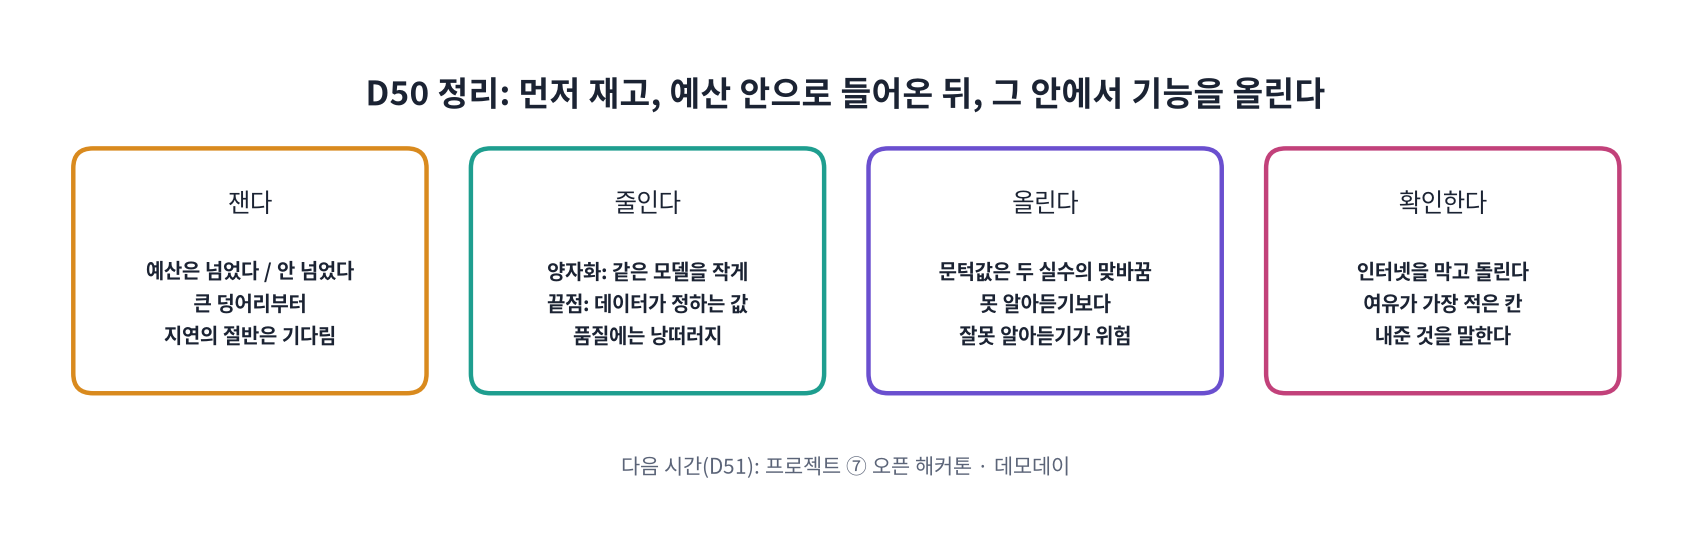

| 오늘 한 일 | 배운 것 |
|---|---|
| 카드와 기준 설계 측정 | 예산은 넘었다 / 안 넘었다로 답한다. 고치기 전에 지금 얼마나 쓰는지 먼저 잰다 |
| 가계부(크기 · 지연의 내역) | 큰 덩어리부터 본다. 지연의 절반은 계산이 아니라 기다리는 시간이었다 |
| 양자화 | 같은 모델을 더 작게. 바꾼 뒤에는 기능을 다시 잰다 |
| 끝점 | 데이터(말 안의 쉼)가 정하는 값. 줄이면 빨라지고, 너무 줄이면 말이 잘린다 |
| 말하기 단계 | 품질에는 낭떠러지가 있다. 잴 때마다 흔들리는 값은 여유를 두고 고른다 |
| 화자 검증 | 문턱값은 두 가지 실수를 맞바꾼다. 틈이 넓은 모델은 값이 더 든다 |
| 용어 맞추기 · 핫워드 | 못 알아듣는 것보다 잘못 알아듣는 것이 위험하다. 좋아졌나와 얼마 들었나를 함께 묻는다 |
| 최종 측정 | 오프라인은 끊어 놓고 돌려서 확인한다 |

**오늘의 산출물**: 제출 코드 · `hana_result.json` · `hana_card.md`

### ✍️ 회고 (5분 · 아래에 직접 적어 보세요)

1. 예산을 맞추려고 **내준 것** 가운데 가장 아까웠던 것은 무엇인가요? 그래도 그렇게 정한 까닭은요?
2. 값을 바꿨는데 **예상과 다르게** 나온 실험이 있었나요? 무엇을 예상했고 무엇이 나왔나요?
3. 이 비서를 실제 공장에 넣는다면, 오늘 재지 않은 것 가운데 **가장 먼저 재야 할 것**은 무엇인가요?

> ⚠️ **오늘 하지 않은 것**: 전용 깨움말 검출기(D44. 오늘은 받아쓴 글로 깨움말을 확인했습니다. 실제 기기는 가벼운 검출기를 늘 켜 두고 깨어난 뒤에만 받아쓰기를 돌립니다), 실제 사람의 목소리(작업자와 외부인 모두 합성한 목소리입니다. 화자 검증의 점수는 실제 사람에게서 다르게 나옵니다), 녹음을 틀어 속이는 공격을 막는 일, 실제 기기에서의 측정(RAM과 지연은 Colab에서 잰 뒤 기준 기계의 값으로 바꾼 것입니다. 라즈베리 파이 같은 기기에서는 다시 재야 합니다), 실시간으로 흘려 넣으며 듣기(시나리오 음성을 한 번에 넣고 끝점을 계산했습니다), 설비 번호 알아듣기(설비 이름의 낱말로만 찾습니다. 3번 펌프와 4번 펌프가 함께 있는 현장이라면 숫자도 맞춰야 합니다), 전력과 발열.

**내일(D51)은 오픈 해커톤 · 데모데이입니다.** 주제는 팀이 정합니다. D32부터 오늘까지 만든 것 가운데 무엇을 꺼내 쓸지 오늘 저녁에 생각해 오세요. 오늘의 측정 셀처럼, **"됐다"를 숫자로 보여 줄 방법**을 함께 준비하면 발표가 쉬워집니다.